**Team members**

| Student ID | Name | Email |
|---|---|---|
| 0001222264 | Simone Magli | simone.magli3@studio.unibo.it |
| 0001226296 | Francesco Giuseppe Ielo | francesco.ielo3@studio.unibo.it |

# Assignment Module 2: Aircraft Classification

The goal of this assignment is to implement a neural network that classifies images of 100 aircraft model variants from the [Fine-Grained Visual Classification of Aircraft (**FGVC-Aircraft**) dataset](https://www.robots.ox.ac.uk/~vgg/data/fgvc-aircraft/). The assignment is divided into two parts: first, you will be asked to implement your own neural network for image classification from scratch; then, you will fine-tune a pretrained network provided by PyTorch.

![](https:///raw.githubusercontent.com/CVLAB-Unibo/ipcv-assignment-2/master/fgvc_aircraft_variants.svg)

## 0. Setup

**Running this notebook.** As submitted (`ALLOW_TRAINING = False`), the notebook trains nothing. Executed top to bottom, it:
- downloads the dataset from a copy shared by link on Google Drive, or from the official Oxford server if that fails
  (Section 1.1);
- downloads the results of all our experiments, which we published as a zip shared by link (Section 2.5): configurations,
  training histories, accuracies and the checkpoints of the three final models;
- rebuilds every table and plot from these files.

It needs no account and no access to our files, and takes a few minutes, mostly to download and cache the dataset.
A GPU is not required (it only speeds up the short sanity check of P1.2).

**Re-training (optional).** With `ALLOW_TRAINING = True`, experiments whose results are not available are trained. Each run
is saved in its own folder, `RUNS_DIR/<AUTHOR>_<run name>/`, with its configuration, training history, results and
checkpoints. By default `RUNS_DIR` is on the temporary disk of the Colab machine, which is erased when the session ends.
With `DRIVE_BACKUP = True` it is on your own Google Drive instead, so that a run interrupted by a disconnection resumes from
its last checkpoint. Training can also be monitored live on Weights & Biases (`USE_WANDB`, off in all our runs).

**How we worked.** We developed this notebook together, keeping it in sync through a shared GitHub repository (push/pull).
Each of us trained part of the experiments on their own Colab account with `DRIVE_BACKUP = True`; the runs of both were
then collected in the published zip, which is why every run folder is prefixed by its author.

In [1]:
# ----------------------------------------------------------------------------
AUTHOR        = "simone"   # your name, without "_": saved folders are <AUTHOR>_<run name>
SEED          = 42
DETERMINISTIC = False      # True: deterministic cuDNN kernels (bit-exact runs, but slower training)
# data
DATA_ROOT     = "/content/data"  # local disk of the Colab VM (fast)
SHORT_SIDE    = 256              # short side of the cached images, in pixels
BANNER_PX     = 20               # height of the copyright banner at the bottom (see 1.3.3)
DATASET_GDOWN_ID = "17e0hrO-bQGsdEsQf0WExi_8hkHVBzZb7"          # optional: Drive file ID of a copy of fgvc-aircraft-2013b.tar.gz shared by link
# storage
DRIVE_BACKUP  = False                             # True: keep runs and caches on your own Drive (recommended to train)
DRIVE_DIR     = "/content/drive/MyDrive/IPCV_A2"  # folder on your own Drive (used only if DRIVE_BACKUP)
PUBLISHED_RUNS = {"final": "14uju3SuqZCUf2vDj9KmkGmK6Mq0R6m3y"}  # {label: Drive file ID} of the zip created by publish_runs() and shared by link
# training
ALLOW_TRAINING = False  # False: completed runs (local or published) are loaded, missing runs are skipped, nothing is trained
# logging
USE_WANDB     = False
WANDB_PROJECT = "ipcv-a2-fgvc-aircraft"
WANDB_ENTITY  = None  # None = your personal W&B account
# ----------------------------------------------------------------------------
STORE_DIR     = DRIVE_DIR if DRIVE_BACKUP else "/content/store"
CACHE_DIR     = f"{STORE_DIR}/cache"
RUNS_DIR      = f"{STORE_DIR}/runs"
PUBLISHED_DIR = "/content/published_runs"  # published runs downloaded with gdown (read only)

In [2]:
if DRIVE_BACKUP:
    from google.colab import drive
    drive.mount("/content/drive")

In [3]:
import gc
import importlib
import io
import json
import math
import os
import random
import shutil
import subprocess
import sys
import time
import uuid
import zipfile
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision.datasets import FGVCAircraft
from torchvision.datasets.utils import download_url, extract_archive
from torchvision.transforms import v2
from torchvision.transforms import functional as TF
from tqdm import tqdm

for d in (CACHE_DIR, RUNS_DIR, PUBLISHED_DIR):
    os.makedirs(d, exist_ok=True)


def import_or_install(package: str):
    try:
        return importlib.import_module(package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)
        return importlib.import_module(package)


gdown = import_or_install("gdown")
if USE_WANDB:
    wandb = import_or_install("wandb")
    try:  # the API key is read from the Colab secrets, so that it never appears in the notebook
        from google.colab import userdata
        os.environ["WANDB_API_KEY"] = userdata.get("WANDB_API_KEY")
    except Exception as e:
        print(f"WANDB_API_KEY not found in the Colab secrets ({type(e).__name__}): wandb.login() will ask for it")
    wandb.login()


def fix_random(seed: int) -> None:
    """Fix all the possible sources of randomness. With DETERMINISTIC = False cuDNN may choose faster, non-deterministic
    kernels: runs are then reproducible only up to small numerical differences."""
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = not DETERMINISTIC
    torch.backends.cudnn.deterministic = DETERMINISTIC


fix_random(SEED)
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"
print(f"torch {torch.__version__} | device: {device} ({GPU_NAME}) | CPU cores: {os.cpu_count()}")
print(f"runs: {RUNS_DIR} | W&B: {'on' if USE_WANDB else 'off'}")

torch 2.11.0+cu130 | device: cuda (Tesla T4) | CPU cores: 8
runs: /content/store/runs | W&B: off


## Dataset

Download and acces the dataset through its official [PyTorch `FGVCAircraft` class](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.FGVCAircraft.html) (by setting its constructor argument `annotation_level` to `'variant'`).

### 1.1 Download

The archive (≈2.6 GB) is downloaded and extracted on the local disk of the VM once per session. It is downloaded with
`gdown` from a copy shared by link on Google Drive (`DATASET_GDOWN_ID`), usually much faster than the official Oxford
server; if this download fails (e.g. because Google Drive limits the downloads of a shared file), the archive is
downloaded from Oxford instead. With `DRIVE_BACKUP = True`, an archive downloaded from Oxford is also copied to your own
Drive and reused in later sessions.

In [4]:
import tarfile

TAR_NAME = "fgvc-aircraft-2013b.tar.gz"
DATASET_URL = "https://www.robots.ox.ac.uk/~vgg/data/fgvc-aircraft/archives/" + TAR_NAME


def _download_from_drive(file_id, local_tar) -> bool:
    """Downloads the archive with gdown; returns False (instead of failing) if the download does not succeed,
    e.g. when Google Drive limits the downloads of a shared file."""
    print("Downloading the archive from Drive with gdown...")
    try:
        gdown.download(f"https://drive.google.com/uc?id={file_id}", str(local_tar), quiet=False)
    except Exception as e:
        print(f"gdown error: {type(e).__name__}: {e}")
    if local_tar.exists() and tarfile.is_tarfile(local_tar):
        return True
    print("Download from Drive failed: falling back to the Oxford server")
    local_tar.unlink(missing_ok=True)
    return False


def ensure_dataset(data_root) -> None:
    data_root = Path(data_root)
    if (data_root / "fgvc-aircraft-2013b").is_dir():
        print("Dataset already extracted.")
        return
    data_root.mkdir(parents=True, exist_ok=True)
    local_tar = data_root / TAR_NAME
    local_tar.unlink(missing_ok=True)  # never reuse a partial download of a previous attempt
    drive_tar = Path(STORE_DIR) / "data" / TAR_NAME if DRIVE_BACKUP else None
    t0 = time.time()
    if DATASET_GDOWN_ID and _download_from_drive(DATASET_GDOWN_ID, local_tar):
        pass
    elif drive_tar is not None and drive_tar.exists():
        print("Copying the archive from your Drive...")
        shutil.copy(drive_tar, local_tar)
    else:
        print("Downloading the archive from Oxford...")
        download_url(DATASET_URL, str(data_root), filename=TAR_NAME)
        if drive_tar is not None:
            print("Saving a copy on your Drive, for the next sessions...")
            drive_tar.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy(local_tar, drive_tar)
    print("Extracting...")
    extract_archive(str(local_tar), str(data_root))
    local_tar.unlink()
    print(f"Done in {time.time() - t0:.0f}s")


ensure_dataset(DATA_ROOT)

Downloading...
From (original): https://drive.google.com/uc?id=17e0hrO-bQGsdEsQf0WExi_8hkHVBzZb7
From (redirected): https://drive.google.com/uc?id=17e0hrO-bQGsdEsQf0WExi_8hkHVBzZb7&confirm=t&uuid=d4840f30-c146-4d65-8a56-0669ad87f021
To: /content/data/fgvc-aircraft-2013b.tar.gz
100%|██████████| 2.75G/2.75G [00:27<00:00, 101MB/s]


Extracting...
Done in 43s


### 1.2 In-memory cache

The original images are large JPEGs: decoding and resizing them at every epoch would make the CPU, not the GPU, the bottleneck.
We therefore preprocess each split once — crop the copyright banner, resize so that the short side is `short_side`
(keeping the aspect ratio) — and keep the result in RAM as `uint8` tensors. Random augmentations are still applied on the fly
at every epoch (Section 1.4).

There is one cache per resolution: `get_cache(split, short_side)` builds it the first time it is needed and saves it in
`CACHE_DIR`, so that it is built only once per session (only once overall with `DRIVE_BACKUP = True`). All the experiments use `SHORT_SIDE = 256`
unless their configuration sets a different `short_side`, which is needed for higher input resolutions (Part 2B): e.g. a
448×448 center crop needs a short side of 512. At the default resolution images are stored decoded (≈3 GB of RAM); caches with a larger short side are stored as
JPEG (quality 95), about 10× smaller (≈1–2 GB at 512 px instead of 12 GB), and decoded on the fly by the data loader
workers.

In [5]:
RAW_MAX_SHORT_SIDE = 256  # caches with a larger short side are stored as JPEG to save RAM
JPEG_QUALITY = 95


def _load_one(path, short_side, banner_px, jpeg):
    img = Image.open(path).convert("RGB")
    w, h = img.size
    if banner_px > 0:
        img = img.crop((0, 0, w, h - banner_px))
    img = TF.resize(img, short_side, antialias=True)
    if jpeg:  # encoded bytes, as a 1-D uint8 tensor
        buf = io.BytesIO()
        img.save(buf, format="JPEG", quality=JPEG_QUALITY)
        return torch.frombuffer(bytearray(buf.getvalue()), dtype=torch.uint8), (w, h)
    return TF.pil_to_tensor(img).contiguous(), (w, h)


def _check_ram(n_images, short_side, jpeg, what):
    """Stops with a clear message, instead of crashing the runtime, if the cache would not fit in the free RAM."""
    import psutil
    need = n_images * 3 * short_side * short_side * DATA_ASPECT / 1e9  # images are ~1.5x wider than tall
    need = need / 8 if jpeg else need  # conservative size of a JPEG at quality 95
    free = psutil.virtual_memory().available / 1e9
    if need > 0.85 * free:
        raise MemoryError(f"{what} needs ~{need:.1f} GB of RAM but only {free:.1f} GB are free: "
                          "use a High-RAM runtime, or free the unused caches with release_caches()")


def build_or_load_cache(split, data_root, cache_dir, short_side, banner_px, num_threads=8) -> dict:
    jpeg = short_side > RAW_MAX_SHORT_SIDE
    fmt = f"_jpeg{JPEG_QUALITY}" if jpeg else ""
    cache_path = Path(cache_dir) / f"{split}_s{short_side}_b{banner_px}{fmt}.pt"
    ds = FGVCAircraft(root=data_root, split=split, annotation_level="variant", download=False)
    _check_ram(len(ds), short_side, jpeg, f"the {split} cache at {short_side} px")
    if cache_path.exists():
        t0 = time.time()
        cache = torch.load(cache_path)
        print(f"[{split}, {short_side} px] loaded {len(cache['labels'])} images from cache in {time.time() - t0:.0f}s")
        return cache
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=num_threads) as ex:
        results = list(tqdm(ex.map(lambda p: _load_one(p, short_side, banner_px, jpeg), ds._image_files),
                            total=len(ds), desc=f"{split}, {short_side} px"))
    cache = {"images": [r[0] for r in results], "labels": list(ds._labels), "orig_sizes": [r[1] for r in results],
             "classes": list(ds.classes), "format": "jpeg" if jpeg else "raw"}
    print(f"[{split}, {short_side} px] {len(ds)} images processed in {time.time() - t0:.0f}s")
    torch.save(cache, cache_path)
    return cache


_CACHES = {}  # (split, short_side) -> cache


def get_cache(split, short_side=SHORT_SIDE) -> dict:
    """Cache of a split at a given resolution: built, or loaded from CACHE_DIR, only the first time it is needed."""
    if (split, short_side) not in _CACHES:
        _CACHES[(split, short_side)] = build_or_load_cache(split, DATA_ROOT, CACHE_DIR, short_side, BANNER_PX)
    return _CACHES[(split, short_side)]


def release_caches(short_side) -> None:
    """Frees the RAM used by the caches at the given resolution."""
    for key in [k for k in _CACHES if k[1] == short_side]:
        del _CACHES[key]
    gc.collect()


DATA_ASPECT = 1.5  # median width / height of the dataset (Section 1.3.2)
caches = {s: get_cache(s) for s in ["train", "val", "test"]}  # default resolution, used by the data exploration
classes = caches["train"]["classes"]
num_classes = len(classes)
ram_gb = sum(im.numel() for c in caches.values() for im in c["images"]) / 1e9
print(f"{num_classes} classes | cache size in RAM: {ram_gb:.2f} GB")

train, 256 px: 100%|██████████| 3334/3334 [00:10<00:00, 316.87it/s]


[train, 256 px] 3334 images processed in 11s


val, 256 px: 100%|██████████| 3333/3333 [00:10<00:00, 323.99it/s]


[val, 256 px] 3333 images processed in 10s


test, 256 px: 100%|██████████| 3333/3333 [00:10<00:00, 324.70it/s]


[test, 256 px] 3333 images processed in 10s
100 classes | cache size in RAM: 2.97 GB


### 1.3 Data exploration

#### 1.3.1 Splits and class balance

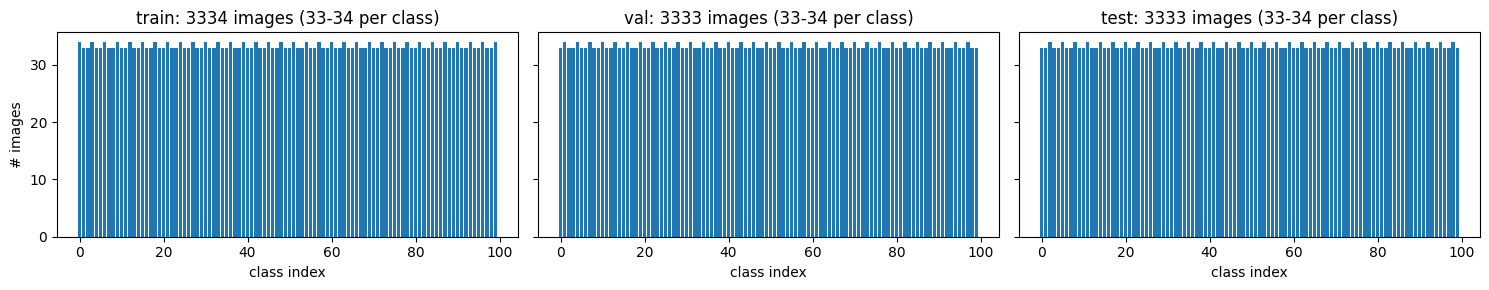

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3), sharey=True)
for a, s in zip(ax, ["train", "val", "test"]):
    cnt = Counter(caches[s]["labels"])
    counts = [cnt[i] for i in range(num_classes)]
    a.bar(range(num_classes), counts)
    a.set_title(f"{s}: {len(caches[s]['labels'])} images ({min(counts)}-{max(counts)} per class)")
    a.set_xlabel("class index")
ax[0].set_ylabel("# images")
plt.tight_layout()
plt.show()

In [7]:
# Data-leakage check: the three splits must not share any image
files = {s: set(FGVCAircraft(DATA_ROOT, split=s, annotation_level="variant")._image_files) for s in ["train", "val", "test"]}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    print(f"{a} ∩ {b}: {len(files[a] & files[b])} shared images")

train ∩ val: 0 shared images
train ∩ test: 0 shared images
val ∩ test: 0 shared images


> *Observations:* the dataset is perfectly balanced (33–34 images per class in every split), so plain accuracy is a fair metric and no class re-weighting is needed. With only ≈33 training images per class, overfitting is the main risk: regularization and data augmentation will be essential.

#### 1.3.2 Image size and aspect ratio

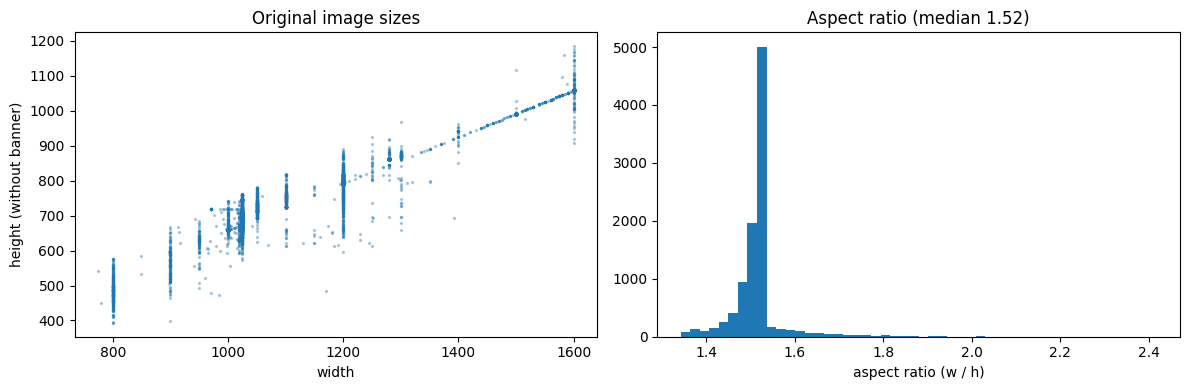

In [8]:
sizes = np.array([s for c in caches.values() for s in c["orig_sizes"]])
w, h = sizes[:, 0], sizes[:, 1] - BANNER_PX
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(w, h, s=2, alpha=0.3)
ax[0].set_xlabel("width"); ax[0].set_ylabel("height (without banner)"); ax[0].set_title("Original image sizes")
ax[1].hist(w / h, bins=50)
ax[1].set_xlabel("aspect ratio (w / h)"); ax[1].set_title(f"Aspect ratio (median {np.median(w / h):.2f})")
plt.tight_layout()
plt.show()

> *Observations:* original images are large (800–1600 px wide), so downsampling to ≈224 px discards fine details. The aspect ratio is tightly concentrated around 1.5 (median 1.52): a square center crop keeps only ≈66% of the width and can cut the nose and tail of the aircraft (see 1.4), which motivates comparing different ways of obtaining the network input.

#### 1.3.3 Copyright banner

The bottom of each original image contains a copyright banner, which carries no information about the aircraft.
The red line marks the crop applied in the cache (`BANNER_PX` pixels from the bottom).

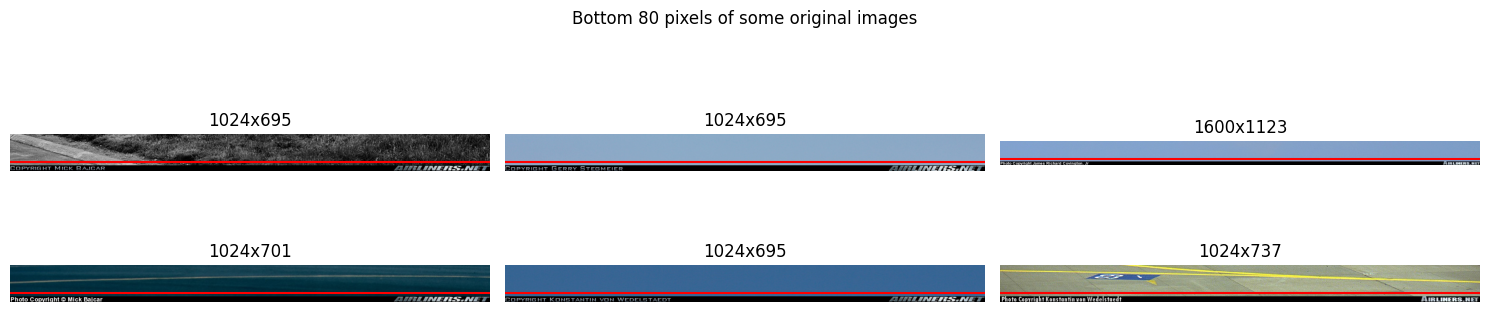

In [9]:
raw = FGVCAircraft(DATA_ROOT, split="train", annotation_level="variant")
idxs = np.linspace(0, len(raw) - 1, 6).astype(int)
fig, ax = plt.subplots(2, 3, figsize=(15, 4))
for a, i in zip(ax.flat, idxs):
    img = np.array(raw[i][0])
    a.imshow(img[-80:])
    a.axhline(80 - BANNER_PX, color="red")
    a.set_title(f"{img.shape[1]}x{img.shape[0]}"); a.axis("off")
plt.suptitle("Bottom 80 pixels of some original images")
plt.tight_layout()
plt.show()

#### 1.3.4 Examples

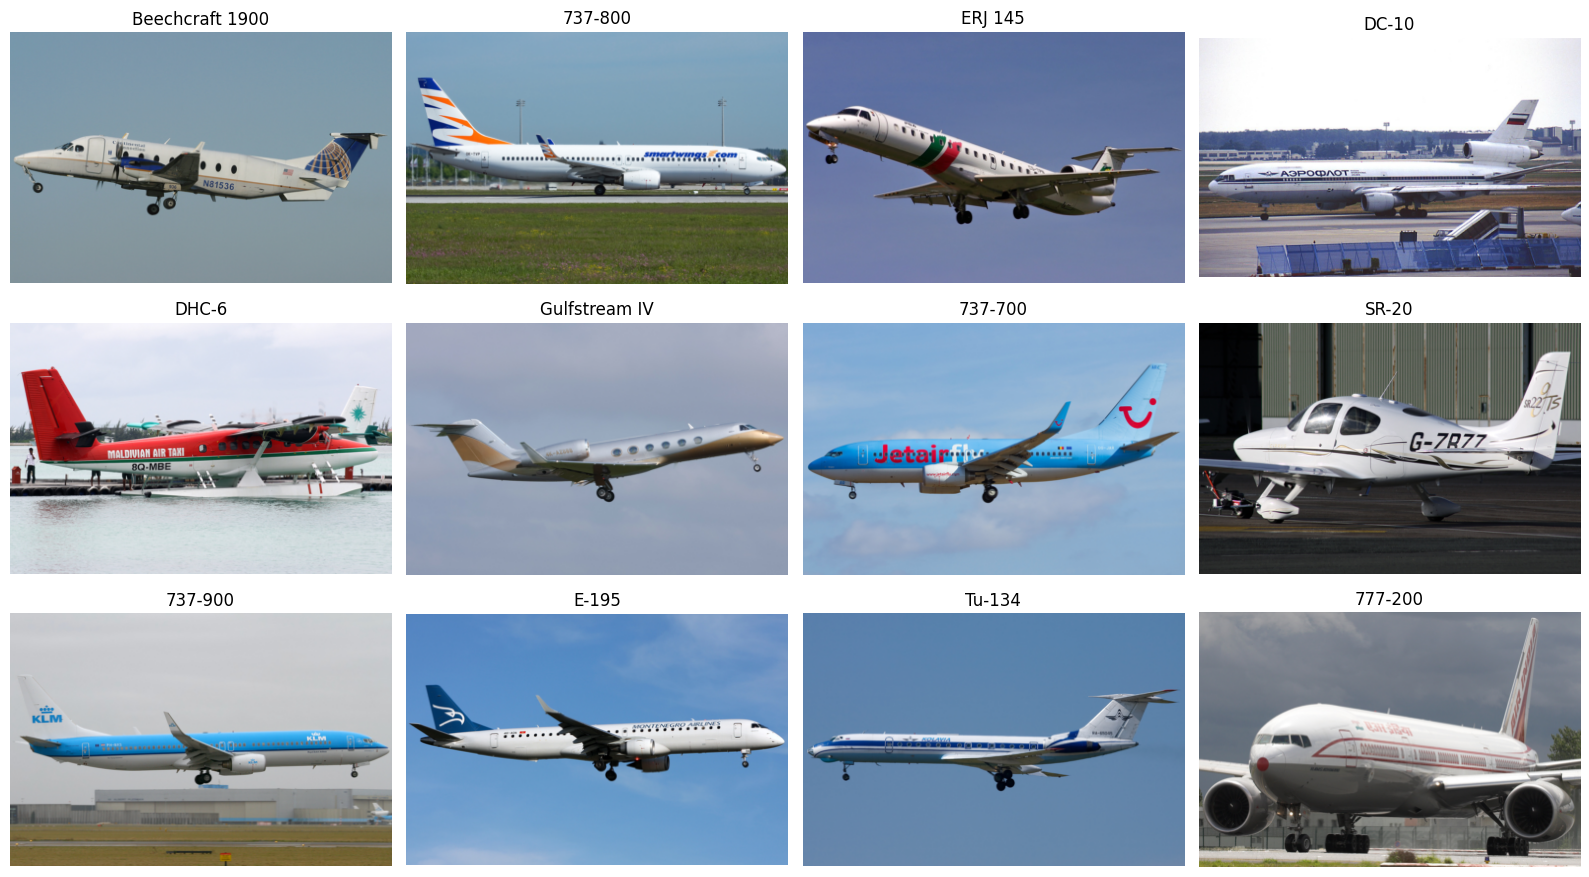

In [10]:
rng = np.random.default_rng(SEED)
train_labels = np.array(caches["train"]["labels"])
fig, ax = plt.subplots(3, 4, figsize=(16, 9))
for a, c in zip(ax.flat, rng.choice(num_classes, 12, replace=False)):
    i = rng.choice(np.where(train_labels == c)[0])
    a.imshow(caches["train"]["images"][i].permute(1, 2, 0))
    a.set_title(classes[c]); a.axis("off")
plt.tight_layout()
plt.show()

Variants of the same family (here: Boeing 737) differ only in small details — this is what makes the task *fine-grained*.

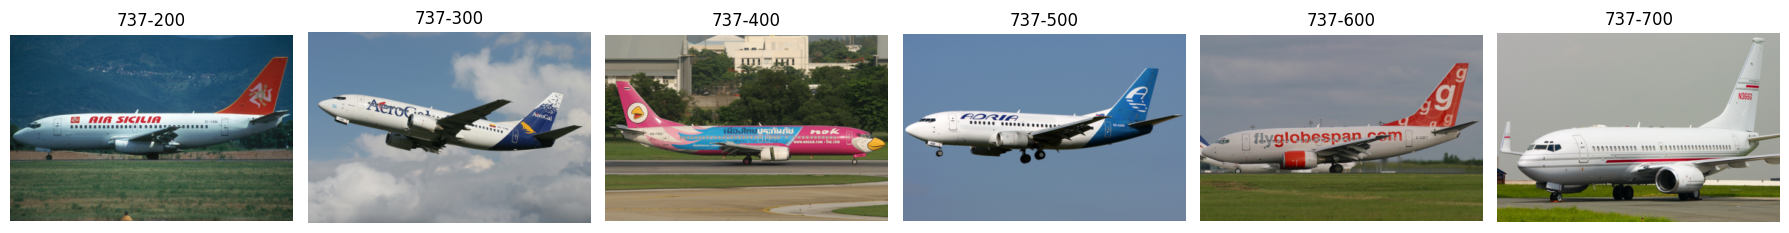

In [11]:
family = [i for i, c in enumerate(classes) if c.startswith("737")][:6]
fig, ax = plt.subplots(1, len(family), figsize=(3 * len(family), 3), squeeze=False)
for a, c in zip(ax[0], family):
    i = np.where(train_labels == c)[0][0]
    a.imshow(caches["train"]["images"][i].permute(1, 2, 0))
    a.set_title(classes[c]); a.axis("off")
plt.tight_layout()
plt.show()

> *Observations:* aircraft are mostly seen from the side, centered and covering most of the image width. Variants of the same family (e.g. 737-200 … 737-700) are nearly identical, differing mainly in fuselage length and small details, so most errors are expected within families. The airline livery is a potential shortcut, since the same airline operates several variants and the same variant appears with many liveries. Some photos are grayscale, which supports the use of color augmentations.

### 1.4 Preprocessing, augmentation and data loaders

Images are normalized with the ImageNet statistics in every part of the assignment, so that the pretrained ResNet-18 of Part 2
receives inputs in the distribution it was trained on, and Part 2A can truly reuse the pipeline of Part 1 unchanged.

Since images are ≈1.5 times wider than tall (Section 1.3.2), we compare three ways of obtaining the network input
(`resize_mode`):
- `"crop"`: resize the short side, then take a central square crop — may cut the nose and the tail of the aircraft;
- `"squash"`: resize the whole image to a square — keeps the whole aircraft, but compresses it horizontally;
- `"rect"`: resize the whole image to a rectangle with aspect ratio 1.5 (e.g. 192×288) — keeps the whole aircraft with almost
  no distortion, at a cost similar to 224×224 (55k vs 50k pixels). This works because networks ending with a global average
  pooling accept inputs of any spatial size.

At training time, `RandomResizedCrop` samples crops whose aspect ratio is centered on the one of the evaluation geometry,
so that aircraft have the same shape at training and test time (1 for `"crop"`, 1.5 for `"squash"` and `"rect"`).
The `"strong"` augmentation adds color jitter and random grayscale conversion, motivated by the livery shortcut and by the
presence of grayscale photos.

In [12]:
from torchvision.io import ImageReadMode, decode_jpeg

IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]


def input_hw(cfg: dict):
    """(H, W) of the network input: img_size is an int (square) or [H, W] (rect)."""
    size = cfg.get("img_size", 224)
    return (size, size) if isinstance(size, int) else tuple(size)


def make_transforms(train: bool, cfg: dict):
    """cfg keys (defaults):
       img_size (224) | resize_mode ("crop" | "squash" | "rect") | aug ("none" | "basic" | "strong" | "trivial") | rrc_scale ((0.35, 1))
    """
    mode, aug = cfg.get("resize_mode", "crop"), cfg.get("aug", "basic")
    h, w = input_hw(cfg)
    if mode == "crop":
        assert h == w, "crop mode needs a square img_size"
        ops, ar = [v2.Resize(int(round(h * 256 / 224)), antialias=True), v2.CenterCrop(h)], 1.0
    elif mode == "squash":
        assert h == w, "squash mode needs a square img_size"
        ops, ar = [v2.Resize((h, w), antialias=True)], DATA_ASPECT
    elif mode == "rect":
        ops, ar = [v2.Resize((h, w), antialias=True)], w / h
    else:
        raise ValueError(mode)
    if train and aug != "none":
        ops = [v2.RandomResizedCrop((h, w), scale=tuple(cfg.get("rrc_scale", (0.35, 1.0))),
                                    ratio=(ar * 3 / 4, ar * 4 / 3), antialias=True),
               v2.RandomHorizontalFlip()]
        if aug == "strong":
            ops += [v2.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3), v2.RandomGrayscale(p=0.1)]
        elif aug == "trivial":  # automatic augmentation policy (Müller & Hutter, ICCV 2021), applied to uint8 images
            ops += [v2.TrivialAugmentWide()]
        elif aug != "basic":
            raise ValueError(aug)
    return v2.Compose(ops + [v2.ToDtype(torch.float32, scale=True), v2.Normalize(IMAGENET_MEAN, IMAGENET_STD)])


class CachedDataset(Dataset):
    def __init__(self, cache: dict, transform=None):
        self.images, self.labels, self.transform = cache["images"], cache["labels"], transform
        self.jpeg = cache.get("format", "raw") == "jpeg"

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        x = self.images[i]
        if self.jpeg:
            x = decode_jpeg(x, mode=ImageReadMode.RGB)
        return (self.transform(x) if self.transform else x), self.labels[i]


MAX_WORKERS = 8  # every worker is a separate process with its own memory


def make_loader(split: str, cfg: dict, train: bool, batch_size=None, seed=SEED):
    """Loader of a split, built on the cache at the resolution cfg["short_side"] (default SHORT_SIDE)."""
    short_side = cfg.get("short_side", SHORT_SIDE)
    h, w = input_hw(cfg)
    needed = int(round(h * 256 / 224)) if cfg.get("resize_mode", "crop") == "crop" else h
    if needed > short_side:  # never upsample the cached images silently
        raise ValueError(f"a {h}x{w} input ({cfg.get('resize_mode', 'crop')}) needs images with short side >= {needed}, "
                         f"but the cache has {short_side}: set short_side in the config")
    ds = CachedDataset(get_cache(split, short_side), make_transforms(train, cfg))
    g = torch.Generator(); g.manual_seed(seed)
    nw = min(os.cpu_count(), MAX_WORKERS)
    return DataLoader(ds, batch_size=batch_size or cfg.get("batch_size", 64), shuffle=train, drop_last=train,
                      num_workers=nw, pin_memory=torch.cuda.is_available(), persistent_workers=nw > 0,
                      generator=g if train else None)


def denormalize(x: torch.Tensor) -> torch.Tensor:
    mean = torch.tensor(IMAGENET_MEAN).view(-1, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(-1, 1, 1)
    return (x.cpu() * std + mean).clamp(0, 1)

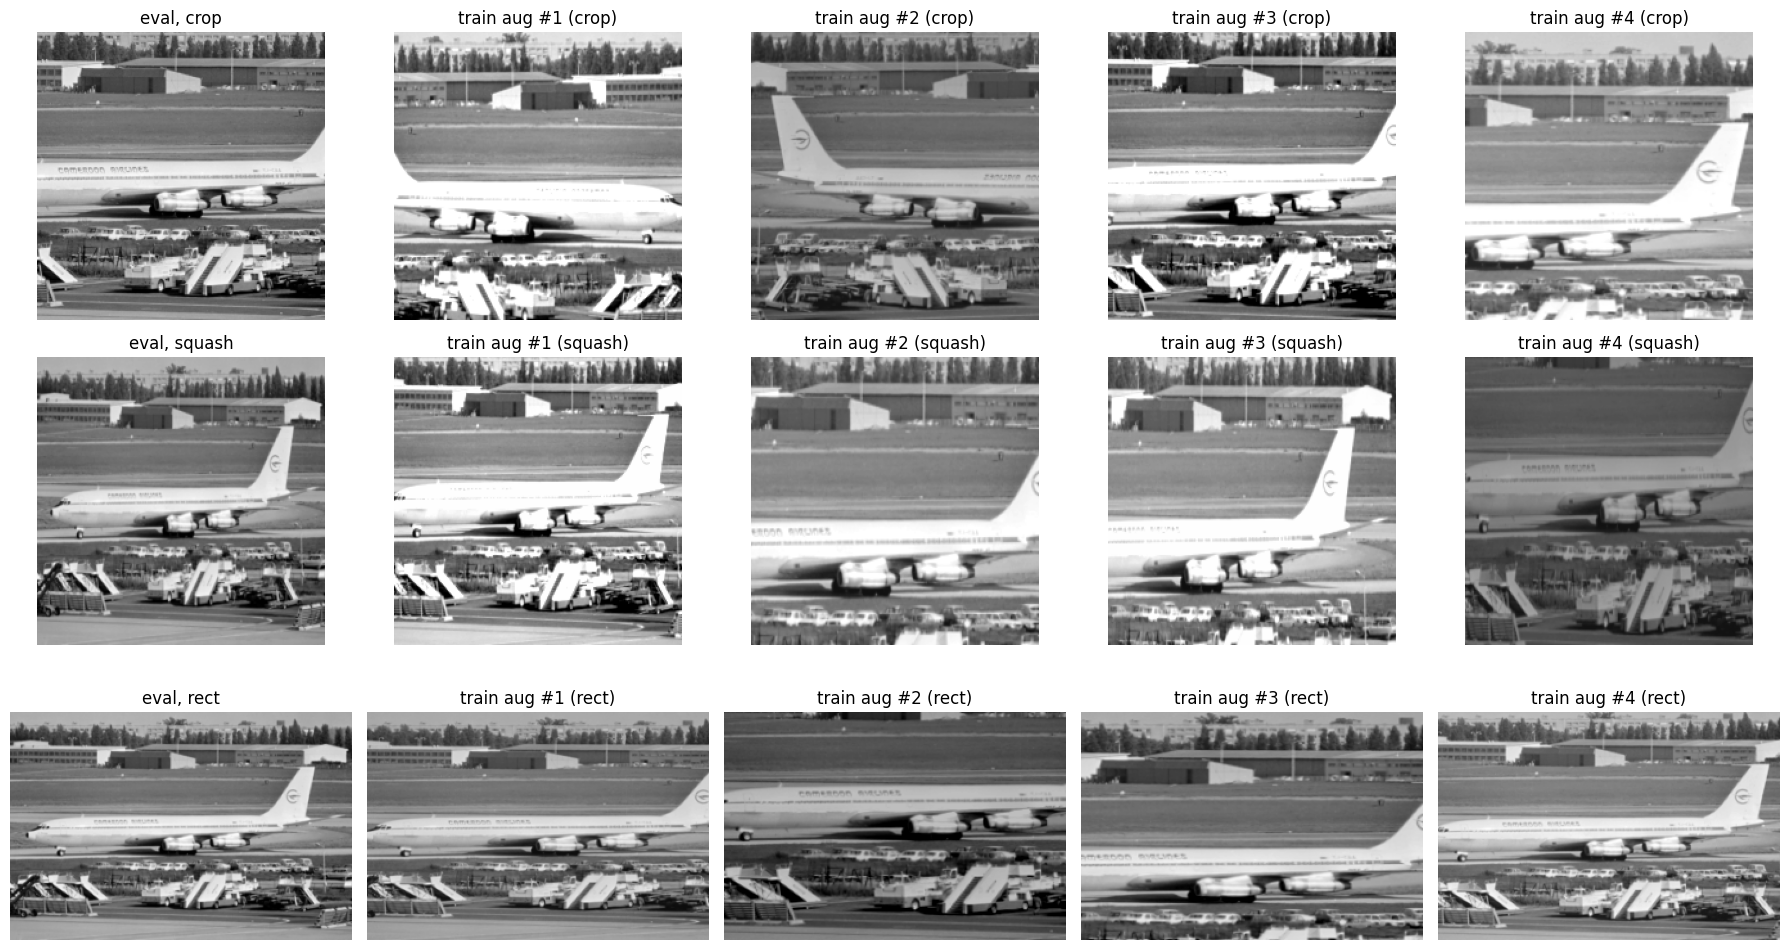

In [13]:
img = caches["train"]["images"][7]
geometries = {"crop": {"resize_mode": "crop", "img_size": 224},
              "squash": {"resize_mode": "squash", "img_size": 224},
              "rect": {"resize_mode": "rect", "img_size": [192, 288]}}
fig, ax = plt.subplots(len(geometries), 5, figsize=(18, 3.3 * len(geometries)))
for row, (name, g) in zip(ax, geometries.items()):
    row[0].imshow(denormalize(make_transforms(False, g)(img)).permute(1, 2, 0)); row[0].set_title(f"eval, {name}")
    t_aug = make_transforms(True, dict(g, aug="strong"))
    for k, a in enumerate(row[1:]):
        a.imshow(denormalize(t_aug(img)).permute(1, 2, 0)); a.set_title(f"train aug #{k + 1} ({name})")
    for a in row:
        a.axis("off")
plt.tight_layout()
plt.show()

> *Observations:* the center crop cuts the nose of the aircraft, squashing keeps it at the cost of a horizontal compression, while the rectangular input keeps the whole aircraft essentially undistorted. Too small random crops keep only a portion of the fuselage and lose discriminative parts, so the lower bound of the crop scale (`rrc_scale`) is treated as a hyperparameter.

## 2. Training utilities

Shared by all parts of the assignment:
- **2.1** optimizer, learning rate schedules (step, cosine with warm-up, one-cycle), MixUp / CutMix;
- **2.2** training loop with mixed precision, model selection on the **validation** split only, checkpoints and history saved
  at every epoch, automatic resume after a disconnection;
- **2.3** `run_experiment`: runs an experiment only if it has not been completed yet — neither locally nor among the published
  runs — otherwise it just loads its results, so the notebook can be executed top to bottom without retraining anything; the
  test split is evaluated once, on the best-validation checkpoint, at the end of each run. Optional live logging to W&B;
- **2.4** plots and tables built from the saved runs (local and published);
- **2.5** downloading and publishing the runs with `gdown`.

### 2.1 Optimizers, schedules and batch mixing

In [14]:
def build_optimizer(params, cfg: dict):
    """`params` is either model.parameters() or a list of parameter groups (e.g. different LRs in Part 2B)."""
    name, lr, wd = cfg.get("optimizer", "sgd"), cfg["lr"], cfg.get("wd", 0.0)
    if name == "sgd":
        return torch.optim.SGD(params, lr=lr, momentum=cfg.get("momentum", 0.9), nesterov=True, weight_decay=wd)
    if name == "adamw":
        return torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    raise ValueError(name)


def build_scheduler(optimizer, cfg: dict, steps_per_epoch: int):
    """All schedules are updated at every step (mini-batch)."""
    name = cfg.get("scheduler", "cosine")
    total = cfg["epochs"] * steps_per_epoch
    warmup = cfg.get("warmup_epochs", 0) * steps_per_epoch
    if name == "onecycle":
        return torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=[g["lr"] for g in optimizer.param_groups],
                                                   total_steps=total)
    if name == "cosine":
        def f(step):
            if step < warmup:
                return (step + 1) / warmup
            return 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, total - warmup)))
    elif name == "step":
        milestones = [m * steps_per_epoch for m in cfg.get("milestones", [])]

        def f(step):
            if step < warmup:
                return (step + 1) / warmup
            return cfg.get("gamma", 0.1) ** sum(step >= m for m in milestones)
    elif name == "constant":
        def f(step):
            return 1.0
    else:
        raise ValueError(name)
    return torch.optim.lr_scheduler.LambdaLR(optimizer, f)


def build_batch_mix(cfg: dict):
    """MixUp / CutMix on whole batches. Returns None if both are disabled."""
    ops = []
    if cfg.get("mixup_alpha", 0) > 0:
        ops.append(v2.MixUp(alpha=cfg["mixup_alpha"], num_classes=num_classes))
    if cfg.get("cutmix_alpha", 0) > 0:
        ops.append(v2.CutMix(alpha=cfg["cutmix_alpha"], num_classes=num_classes))
    if not ops:
        return None
    return ops[0] if len(ops) == 1 else v2.RandomChoice(ops)

### 2.2 Training loop

The validation loss is always the plain cross-entropy (without label smoothing), so that it is comparable across runs.

In [15]:
def save_json(obj, path):
    tmp = f"{path}.tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2)
    os.replace(tmp, path)


def load_json(path):
    with open(path) as f:
        return json.load(f)


@torch.no_grad()
def evaluate(model, loader, return_preds=False):
    model.eval()
    use_amp = device.type == "cuda"
    tot_loss, correct, n, preds, labels = 0.0, 0, 0, [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
            out = model(x)
        tot_loss += F.cross_entropy(out.float(), y, reduction="sum").item()
        p = out.argmax(1)
        correct += (p == y).sum().item()
        n += y.numel()
        if return_preds:
            preds.append(p.cpu()); labels.append(y.cpu())
    res = {"loss": tot_loss / n, "acc": correct / n}
    if return_preds:
        res["preds"], res["labels"] = torch.cat(preds), torch.cat(labels)
    return res


def train_model(model, train_loader, val_loader, cfg, run_dir, params=None, log_fn=None):
    """Trains `model` and writes in `run_dir`: history.json (every epoch), best.pt (best validation accuracy),
    last.pt (full state, to resume after a disconnection). log_fn(dict) is called at the end of every epoch (e.g. W&B)."""
    use_amp = cfg.get("amp", True) and device.type == "cuda"
    optimizer = build_optimizer(model.parameters() if params is None else params, cfg)
    scheduler = build_scheduler(optimizer, cfg, len(train_loader))
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg.get("label_smoothing", 0.0))
    batch_mix = build_batch_mix(cfg)

    history = {k: [] for k in ["epoch", "train_loss", "train_acc", "val_loss", "val_acc", "lr", "epoch_time"]}
    start_epoch, best_acc, best_epoch = 0, -1.0, -1
    last_path = f"{run_dir}/last.pt"
    if os.path.exists(last_path):
        ckpt = torch.load(last_path, map_location=device, weights_only=False)
        model.load_state_dict(ckpt["model"]); optimizer.load_state_dict(ckpt["optimizer"])
        scheduler.load_state_dict(ckpt["scheduler"]); scaler.load_state_dict(ckpt["scaler"])
        history, best_acc, best_epoch, start_epoch = ckpt["history"], ckpt["best_acc"], ckpt["best_epoch"], ckpt["epoch"] + 1
        print(f"Resuming from epoch {start_epoch} (best val acc so far {best_acc:.4f} at epoch {best_epoch})")

    pbar = tqdm(range(start_epoch, cfg["epochs"]), desc=os.path.basename(run_dir), initial=start_epoch, total=cfg["epochs"])
    for epoch in pbar:
        t0 = time.time()
        model.train()
        tot_loss, correct, n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            y_hard = y
            if batch_mix is not None:
                x, y = batch_mix(x, y)  # y becomes a soft label
                y_hard = y.argmax(1)
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                out = model(x)
                loss = criterion(out, y)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            if cfg.get("grad_clip", 0) > 0:
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            tot_loss += loss.item() * y_hard.numel()
            correct += (out.argmax(1) == y_hard).sum().item()
            n += y_hard.numel()

        val = evaluate(model, val_loader)
        for k, v in [("epoch", epoch), ("train_loss", tot_loss / n), ("train_acc", correct / n), ("val_loss", val["loss"]),
                     ("val_acc", val["acc"]), ("lr", optimizer.param_groups[0]["lr"]), ("epoch_time", time.time() - t0)]:
            history[k].append(v)
        if val["acc"] > best_acc:
            best_acc, best_epoch = val["acc"], epoch
            torch.save(model.state_dict(), f"{run_dir}/best.pt")
        save_json(history, f"{run_dir}/history.json")
        torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                    "scaler": scaler.state_dict(), "history": history, "best_acc": best_acc, "best_epoch": best_epoch,
                    "epoch": epoch}, last_path)
        if log_fn is not None:
            log_fn({k: v[-1] for k, v in history.items()})
        pbar.set_postfix(train_acc=f"{correct / n:.3f}", val_acc=f"{val['acc']:.3f}", best=f"{best_acc:.3f}")
    return history, best_acc, best_epoch

### 2.3 Running an experiment

`run_experiment(name, build_model, cfg)` saves everything in `RUNS_DIR/<AUTHOR>_<name>/`. Runs are always referred to by
their name only, whoever trained them: the author is just a piece of information stored with the run, so run names must be
unique within the team. If the run has already been completed, it
only loads its results; if it was interrupted it resumes it. If a run
with the same name exists but with a *different* configuration, it stops with an error, so that results are never silently
mixed up: change the name instead.

With `ALLOW_TRAINING = False` a run that is not available is skipped (`run_experiment` returns `None`) instead of trained.

With `USE_WANDB`, every trained run is also logged to W&B. The W&B run id is stored in the run folder, so a run resumed after
a disconnection continues the same W&B run instead of creating a new one.

In [16]:
def run_dir_of(name):
    """Folder where you train the run `name`."""
    return f"{RUNS_DIR}/{AUTHOR}_{name}"


def find_run_dir(name, required="config.json"):
    """Folder of the run `name` (without author) containing the file `required`, or None if there is none.
    Your runs come first (local, then published), then the published runs of the other team members."""
    found = []
    for base in (RUNS_DIR, PUBLISHED_DIR):
        for folder in os.listdir(base):
            author, _, short = folder.partition("_")
            if short == name and os.path.exists(f"{base}/{folder}/{required}"):
                found.append((author != AUTHOR, base != RUNS_DIR, author, f"{base}/{folder}"))
    if not found:
        return None
    found.sort()
    if found[0][2] != AUTHOR and len({f[2] for f in found}) > 1:
        raise ValueError(f"run '{name}' exists for several authors {sorted({f[2] for f in found})}: rename one of them")
    return found[0][3]


def is_done(name):
    return find_run_dir(name, "results.json") is not None


def wandb_start(full_name, cfg, run_dir):
    """Starts the W&B run of a run folder, or resumes it if the folder already has one (e.g. after a disconnection)."""
    id_path = f"{run_dir}/wandb_id.txt"
    if os.path.exists(id_path):
        with open(id_path) as f:
            run_id = f.read().strip()
    else:
        run_id = uuid.uuid4().hex[:12]
        with open(id_path, "w") as f:
            f.write(run_id)
    run = wandb.init(project=WANDB_PROJECT, entity=WANDB_ENTITY, name=full_name, id=run_id, resume="allow", config=cfg)
    run.define_metric("epoch")
    for k in ["train_loss", "train_acc", "val_loss", "val_acc", "lr", "epoch_time"]:
        run.define_metric(k, step_metric="epoch", summary="max" if k == "val_acc" else "last")
    return run


def run_experiment(name, build_model, cfg, build_params=None, force=False, log_wandb=True):
    """build_model(cfg) -> nn.Module; build_params(model, cfg) -> parameter groups (optional).
    force=True re-trains the run from scratch, even if it is already completed."""
    assert "_" not in AUTHOR, "AUTHOR must not contain '_'"
    run_dir = run_dir_of(name)
    cfg = json.loads(json.dumps(cfg))  # normalize (tuples -> lists) to compare it with the saved one
    force = force and ALLOW_TRAINING  # in read-only mode existing results are always loaded
    existing = None if force else find_run_dir(name)
    if existing:
        saved = {k: v for k, v in load_json(f"{existing}/config.json").items() if k in cfg}
        if saved != cfg:
            raise ValueError(f"'{name}' already exists in {existing} with a different config: "
                             "use another name (or force=True to re-train it).")
        if os.path.exists(f"{existing}/results.json"):
            res = load_json(f"{existing}/results.json")
            where = "local" if existing.startswith(RUNS_DIR) else f"published by {os.path.basename(existing).partition('_')[0]}"
            print(f"[{name}] already completed ({where}): val acc {res['best_val_acc']:.4f} | test acc {res['test_acc']:.4f}")
            return res
    if not ALLOW_TRAINING:
        print(f"[{name}] not available and ALLOW_TRAINING = False: skipped")
        return None
    if force and os.path.exists(run_dir):
        shutil.rmtree(run_dir)  # start from scratch: never resume a checkpoint of a different config

    os.makedirs(run_dir, exist_ok=True)
    fix_random(cfg.get("seed", SEED))
    model = build_model(cfg).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    meta = dict(cfg, author=AUTHOR, gpu=GPU_NAME, n_params=n_params, n_trainable=n_trainable)
    save_json(meta, f"{run_dir}/config.json")
    print(f"[{name}] {n_params / 1e6:.2f}M parameters ({n_trainable / 1e6:.2f}M trainable) on {GPU_NAME}")

    wb = wandb_start(f"{AUTHOR}_{name}", meta, run_dir) if (USE_WANDB and log_wandb) else None
    try:
        train_loader = make_loader("train", cfg, train=True, seed=cfg.get("seed", SEED))
        val_loader = make_loader("val", cfg, train=False, batch_size=128)
        params = build_params(model, cfg) if build_params else None
        history, best_acc, best_epoch = train_model(model, train_loader, val_loader, cfg, run_dir, params,
                                                    log_fn=wb.log if wb else None)

        # The test split is used only here, once, on the checkpoint selected on the validation split
        model.load_state_dict(torch.load(f"{run_dir}/best.pt", map_location=device))
        test_loader = make_loader("test", cfg, train=False, batch_size=128)
        test = evaluate(model, test_loader)
        res = {"best_epoch": best_epoch, "best_val_acc": best_acc, "test_acc": test["acc"], "test_loss": test["loss"],
               "train_acc_at_best": history["train_acc"][best_epoch], "n_params": n_params,
               "minutes": sum(history["epoch_time"]) / 60}
        save_json(res, f"{run_dir}/results.json")
    except BaseException:
        if wb:
            wb.finish(exit_code=1)  # shown as failed on W&B; the next call resumes the same W&B run
        raise
    finally:
        # shut down the worker processes of the loaders (persistent workers would otherwise outlive the run)
        train_loader = val_loader = test_loader = None
        gc.collect()
    if wb:
        wb.summary.update({f"final/{k}": v for k, v in res.items()})
        wb.finish()
    print(f"[{name}] best epoch {best_epoch} | val acc {best_acc:.4f} | test acc {test['acc']:.4f}")
    return res


def load_trained_model(name, build_model):
    run_dir = find_run_dir(name, "best.pt")
    if run_dir is None:
        raise FileNotFoundError(f"no checkpoint for run '{name}' (was it published with its checkpoint?)")
    cfg = load_json(f"{run_dir}/config.json")
    model = build_model(cfg).to(device)
    model.load_state_dict(torch.load(f"{run_dir}/best.pt", map_location=device))
    return model.eval(), cfg

### 2.4 Plots and tables from saved runs

In the tables, `minutes` is the training time of a run on the GPU in the `gpu` column (T4, L4 or A100, depending on
the Colab session): training times are only compared between runs on the same GPU.

In [17]:
import pandas as pd


def list_runs():
    """All the saved runs (yours and the published ones): {name: folder}."""
    runs = {}
    for base in (RUNS_DIR, PUBLISHED_DIR):
        for folder in sorted(os.listdir(base)):
            name = folder.partition("_")[2]
            if os.path.exists(f"{base}/{folder}/history.json"):
                runs.setdefault(name, f"{base}/{folder}")
    return runs


def _load(name):
    d = find_run_dir(name)
    if d is None:
        raise FileNotFoundError(f"run '{name}' not found")
    res = load_json(f"{d}/results.json") if os.path.exists(f"{d}/results.json") else {}
    return load_json(f"{d}/config.json"), load_json(f"{d}/history.json"), res


def _available(names, labels=None):
    """Keeps the runs that exist (even if still in progress) and reports the missing ones."""
    labels = labels or names
    exists = lambda n: find_run_dir(n, "history.json") is not None
    missing = [n for n in names if not exists(n)]
    if missing:
        print(f"Not available, skipped: {missing}")
    keep = [(n, l) for n, l in zip(names, labels) if exists(n)]
    return [n for n, _ in keep], [l for _, l in keep]


def plot_runs(names, labels=None, title=None):
    """Loss, accuracy (dashed = train, solid = validation) and learning rate of some runs."""
    names, labels = _available(names, labels)
    if not names:
        return
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
    for name, label in zip(names, labels):
        _, h, _ = _load(name)
        line, = ax[0].plot(h["epoch"], h["val_loss"], label=label)
        c = line.get_color()
        ax[0].plot(h["epoch"], h["train_loss"], "--", color=c, alpha=0.6)
        ax[1].plot(h["epoch"], h["val_acc"], color=c, label=label)
        ax[1].plot(h["epoch"], h["train_acc"], "--", color=c, alpha=0.6)
        ax[2].plot(h["epoch"], h["lr"], color=c, label=label)
    ax[0].set_title("loss (dashed: training, solid: validation)")
    ax[1].set_title("accuracy (dashed: training, solid: validation)")
    ax[2].set_title("learning rate")
    for a in ax:
        a.set_xlabel("epoch"); a.grid(alpha=0.3)
    ax[1].legend(fontsize=8)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def results_table(names, labels=None, reference=None):
    """One row per run; `reference` (a run name) adds the differences in accuracy w.r.t. that run."""
    names, labels = _available(names, labels)
    if not names:
        return pd.DataFrame()
    rows = []
    for name, label in zip(names, labels):
        cfg, h, res = _load(name)
        rows.append({"run": label, "params (M)": cfg.get("n_params", float("nan")) / 1e6,
                     "epochs": len(h["epoch"]), "best epoch": res.get("best_epoch"),
                     "train acc @best": res.get("train_acc_at_best"), "val acc": res.get("best_val_acc"),
                     "test acc": res.get("test_acc"), "minutes": res.get("minutes"), "gpu": cfg.get("gpu")})
    df = pd.DataFrame(rows).set_index("run")
    if reference is not None and is_done(reference):  # decisions are taken on the validation accuracy; Δ test is only reported
        ref = _load(reference)[2]
        df["Δ val acc"] = df["val acc"] - ref.get("best_val_acc")
        df["Δ test acc"] = df["test acc"] - ref.get("test_acc")
    return df.style.format(precision=3, na_rep="-")

### 2.5 Published runs

`publish_runs()` collects the completed runs of a runs folder in a zip file: the json files of every run (configuration,
history, results) and the `best.pt` checkpoints of the final models of Part 1, 2A and 2B, so that they can also be
evaluated without retraining. If the same run was trained by more than one team member, only one copy is kept (the one of
`AUTHOR`, as `find_run_dir` does). Once the zip is shared on Drive as *anyone with the link*, its file ID goes in
`PUBLISHED_RUNS`, and `fetch_published_runs()` downloads it with `gdown` and extracts it in `PUBLISHED_DIR`. If the download fails (e.g.
because of the download quota of Google Drive), the cell stops with the instructions to download the zip by hand and
upload it to Colab.

`wandb_backfill()` logs to W&B the completed local runs that were trained without it.

In [18]:
RUN_FILES = ["config.json", "history.json", "results.json"]


def publish_runs(zip_name="runs_final.zip", with_checkpoints=(), runs_dir=None, out_dir=None):
    """Zips every completed run of `runs_dir` (default: RUNS_DIR), whoever trained it: the json files of each run and
    the best.pt checkpoint of the runs listed in `with_checkpoints` (run names, without author). If a run name exists
    for several authors, the copy of AUTHOR is kept (otherwise the first one), as find_run_dir does.
    The zip is written in `out_dir` (default: STORE_DIR)."""
    runs_dir, out_dir = runs_dir or RUNS_DIR, out_dir or STORE_DIR
    chosen = {}  # run name -> folder
    for folder in sorted(os.listdir(runs_dir)):
        author, _, name = folder.partition("_")
        if not name or not os.path.exists(f"{runs_dir}/{folder}/results.json"):
            continue
        if name not in chosen or author == AUTHOR:
            chosen[name] = folder
    missing = set(with_checkpoints) - set(chosen)
    if missing:
        raise ValueError(f"not completed: {sorted(missing)}")
    tmp = f"/content/{zip_name}"
    with zipfile.ZipFile(tmp, "w", zipfile.ZIP_DEFLATED) as z:
        for name, folder in sorted(chosen.items()):
            for f in RUN_FILES + (["best.pt"] if name in with_checkpoints else []):
                z.write(f"{runs_dir}/{folder}/{f}", f"{folder}/{f}")
    os.makedirs(out_dir, exist_ok=True)
    shutil.copyfile(tmp, f"{out_dir}/{zip_name}")  # overwrite in place: the Drive file keeps its ID
    print(f"{len(chosen)} runs ({len(with_checkpoints)} with checkpoint), {os.path.getsize(tmp) / 1e6:.1f} MB "
          f"-> {out_dir}/{zip_name}")


def fetch_published_runs(sources=None):
    """Downloads with gdown the zip files in `sources` ({label: Drive file ID}) and extracts them in PUBLISHED_DIR.
    A zip already present in /content (e.g. downloaded from the link and uploaded by hand) is used as it is."""
    for label, file_id in (PUBLISHED_RUNS if sources is None else sources).items():
        if not file_id:
            print(f"[{label}] no Drive file ID in PUBLISHED_RUNS: skipped")
            continue
        zip_path = f"/content/published_{label}.zip"
        if not os.path.exists(zip_path):
            try:
                gdown.download(f"https://drive.google.com/uc?id={file_id}", zip_path, quiet=True)
            except Exception as e:
                print(f"[{label}] gdown error: {type(e).__name__}: {e}")
        if not (os.path.exists(zip_path) and zipfile.is_zipfile(zip_path)):
            if os.path.exists(zip_path):
                os.remove(zip_path)  # never keep a partial download
            msg = (f"[{label}] the published runs could not be downloaded (e.g. because of the download quota of Google "
                   f"Drive). Download https://drive.google.com/file/d/{file_id} by hand, upload it to Colab as {zip_path} "
                   "and execute this cell again.")
            if ALLOW_TRAINING:
                print(msg + " Otherwise, the missing runs will be trained.")
                continue
            raise RuntimeError(msg)
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(PUBLISHED_DIR)
            n = len({p.split("/")[0] for p in z.namelist()})
        print(f"[{label}] {n} runs extracted in {PUBLISHED_DIR}")


def wandb_backfill(prefix=f"{AUTHOR}_"):
    """Logs to W&B the completed local runs that have no W&B run yet (e.g. trained before enabling W&B)."""
    for full_name in sorted(os.listdir(RUNS_DIR)):
        d = f"{RUNS_DIR}/{full_name}"
        if not full_name.startswith(prefix) or not os.path.exists(f"{d}/results.json") or os.path.exists(f"{d}/wandb_id.txt"):
            continue
        cfg, h, res = load_json(f"{d}/config.json"), load_json(f"{d}/history.json"), load_json(f"{d}/results.json")
        run = wandb_start(full_name, cfg, d)
        for i in range(len(h["epoch"])):
            run.log({k: v[i] for k, v in h.items()})
        run.summary.update({f"final/{k}": v for k, v in res.items()})
        run.finish()
        print(f"[{full_name}] logged to W&B")


fetch_published_runs()
if USE_WANDB:
    wandb_backfill()

[final] 54 runs extracted in /content/published_runs


## Part 1: design your own network

Your goal is to implement a convolutional neural network for image classification and train it from scratch on `FGVCAircraft`. You should consider yourselves satisfied once you obtain a classification accuracy on the test split of ~50%. You are free to achieve this however you want, except for a few rules you must follow:

- Compile this notebook by displaying the results obtained by the best model you found throughout your experimentation; then show how, by removing some of its components, its performance drops. In other words, do an *ablation study* to prove that your design choices have a positive impact on the final result.

- Do not instantiate an off-the-self PyTorch network. Instead, construct your network as a composition of existing PyTorch layers. In more concrete terms, you can use e.g. `torch.nn.Linear`, but you cannot use e.g. `torchvision.models.alexnet`.

- Show your results and ablations with plots, tables, images, etc. — the clearer, the better.

Don't be too concerned with your model performance: the ~50% is just to give you an idea of when to stop. Keep in mind that a thoroughly justified model with lower accuracy will be rewarded more points than a poorly experimentally validated model with higher accuracy.

### P1.1 Network design

All the networks of Part 1 belong to one configurable family, `AircraftNet`, so that every ablation is obtained by changing
a single key of the configuration:

- **stem**: a 3×3 convolution with stride 2 that halves the resolution early, to limit the cost of the following
  layers on large input images;
- **4 stages** with increasing width (`widths`); the first block of every stage halves the resolution with stride 2, so the
  receptive field grows while the cost per stage stays similar. `depths` sets the number of blocks per stage;
- **blocks** (`block`): `"plain"` = two 3×3 conv–BN–ReLU; `"residual"` = the same two convolutions plus a skip connection
  (a 1×1 convolution when the shape changes), as in ResNet (He et al., *Deep Residual Learning for Image Recognition*, CVPR 2016);
- **batch normalization** after every convolution, which can be switched off (`bn`);
- **head**: global average pooling → dropout (`dropout`) → linear classifier. Global average pooling makes the network
  independent of the input size (needed for the rectangular input) and avoids a large, overfitting-prone fully connected layer.

Weights are initialized with the Kaiming (He) initialization, designed for ReLU networks (He et al., *Delving Deep into Rectifiers*, ICCV 2015).

In [19]:
class Block(nn.Module):
    """Two 3x3 convolutions (+ BN + ReLU); with residual=True, a skip connection is added before the last ReLU."""

    def __init__(self, c_in, c_out, stride, residual, bn):
        super().__init__()
        self.residual = residual
        norm = (lambda c: nn.BatchNorm2d(c)) if bn else (lambda c: nn.Identity())
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=not bn)
        self.bn1 = norm(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1, bias=not bn)
        self.bn2 = norm(c_out)
        self.shortcut = None
        if residual and (stride != 1 or c_in != c_out):
            self.shortcut = nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride=stride, bias=not bn), norm(c_out))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + (x if self.shortcut is None else self.shortcut(x))
        return F.relu(out)


class AircraftNet(nn.Module):
    def __init__(self, num_classes, widths=(32, 64, 128, 256), depths=(1, 1, 1, 1), stem_width=32,
                 block="plain", bn=True, dropout=0.0):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, stem_width, 3, stride=2, padding=1, bias=not bn),
                                  nn.BatchNorm2d(stem_width) if bn else nn.Identity(), nn.ReLU(inplace=True))
        layers, c_in = [], stem_width
        for c_out, depth in zip(widths, depths):
            for i in range(depth):
                layers.append(Block(c_in, c_out, stride=2 if i == 0 else 1, residual=(block == "residual"), bn=bn))
                c_in = c_out
        self.stages = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(c_in, num_classes))
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.head(self.stages(self.stem(x)))


def build_aircraftnet(cfg):
    return AircraftNet(num_classes, widths=tuple(cfg.get("widths", (32, 64, 128, 256))),
                       depths=tuple(cfg.get("depths", (1, 1, 1, 1))), stem_width=cfg.get("stem_width", 32),
                       block=cfg.get("block", "plain"), bn=cfg.get("bn", True), dropout=cfg.get("dropout", 0.0))

### P1.2 Baseline configuration and sanity checks

Following A. Karpathy's *A Recipe for Training Neural Networks* (2019), we start from a deliberately simple baseline — plain blocks, basic augmentation,
no label smoothing, no MixUp/CutMix, no dropout — and first verify that the pipeline is correct:
1. with random weights the network should predict an almost uniform distribution, so the initial loss should be close to
   $\ln(100) \approx 4.61$;
2. the network must be able to reach (almost) zero loss on a **single batch**: if it cannot, there is a bug in the data,
   the labels or the model.

parameters: 1.21M | input (32, 3, 192, 288) -> output (32, 100)
initial loss: 4.599 (expected ~4.605)


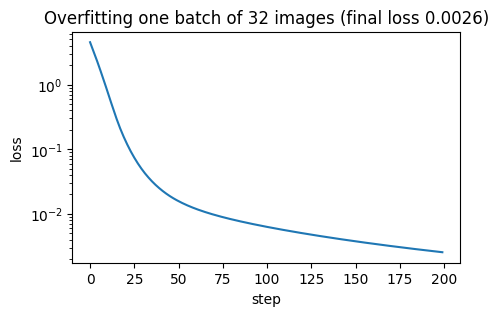

In [20]:
P1_BASE = {
    "seed": SEED,
    # input
    "img_size": [192, 288], "resize_mode": "rect", "aug": "basic", "rrc_scale": [0.35, 1.0],
    # model
    "widths": [32, 64, 128, 256], "depths": [1, 1, 1, 1], "stem_width": 32, "block": "plain", "bn": True, "dropout": 0.0,
    # training
    "batch_size": 64, "epochs": 40, "optimizer": "sgd", "lr": 0.05, "wd": 5e-4,
    "scheduler": "cosine", "warmup_epochs": 2, "label_smoothing": 0.0, "mixup_alpha": 0.0, "cutmix_alpha": 0.0,
}

fix_random(SEED)
model = build_aircraftnet(P1_BASE).to(device)
x, y = next(iter(make_loader("train", dict(P1_BASE, aug="none"), train=True, batch_size=32)))
x, y = x.to(device), y.to(device)
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M | input {tuple(x.shape)} -> output {tuple(model(x).shape)}")

# 1) initial loss
model.eval()
with torch.no_grad():
    print(f"initial loss: {F.cross_entropy(model(x), y).item():.3f} (expected ~{math.log(num_classes):.3f})")

# 2) overfit a single batch
model.train()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
losses = []
for step in range(200):
    loss = F.cross_entropy(model(x), y)
    opt.zero_grad(); loss.backward(); opt.step()
    losses.append(loss.item())
plt.figure(figsize=(5, 3))
plt.plot(losses); plt.yscale("log"); plt.xlabel("step"); plt.ylabel("loss")
plt.title(f"Overfitting one batch of 32 images (final loss {losses[-1]:.4f})")
plt.show()
del model, opt

> *Observations:* the initial loss matches $\ln(100)$ and the network drives the loss on a single batch to ≈0.003 in 200 steps: data, labels and model are consistent, so the pipeline can be trusted.

### P1.3 Baseline

First real training run, which gives a first reference accuracy for the following experiments.

[p1_baseline] already completed (published by simone): val acc 0.3453 | test acc 0.3453


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu
run,,,,,,,,
p1_baseline,1.208,40,38,0.652,0.345,0.345,9.884,Tesla T4


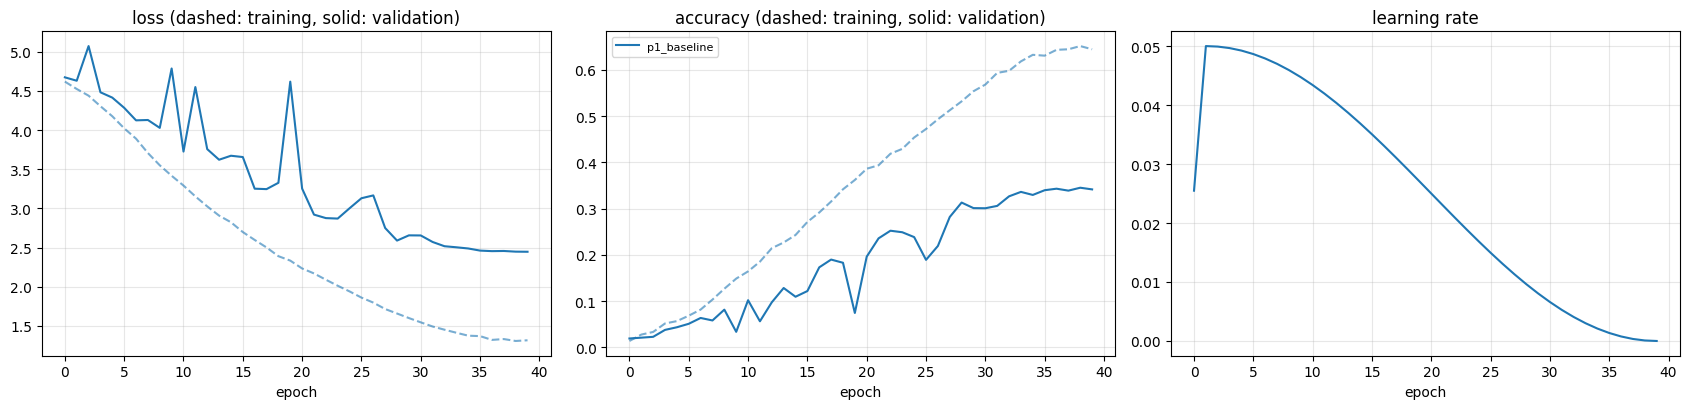

In [21]:
RUN_P1_BASELINE = True

if RUN_P1_BASELINE:
    run_experiment("p1_baseline", build_aircraftnet, P1_BASE)

name = "p1_baseline"
display(results_table([name]))
plot_runs([name])

> *Observations:* the baseline reaches 34.5% validation accuracy. Three issues emerge:
> 1. **large generalization gap**: 65% training vs 35% validation accuracy at the best epoch;
> 2. **limited capacity**: even on the training set (with augmentation) the network only reaches 65%, so it is not able to fit the data;
> 3. **instability at high learning rate**: while the LR is above ≈0.02, the validation loss shows large spikes (epochs 2, 9, 11, 19) although the training loss decreases smoothly; the curves become stable only when the cosine schedule lowers the LR.
>
> Following the recipe, we first increase the capacity of the network until it can fit the training set, then we regularize it.

### P1.4 Increasing the capacity

One change at a time with respect to the baseline, everything else fixed (same 40 epochs, same optimizer and schedule):
- `p1_res`: residual blocks instead of plain blocks — skip connections ease the optimization and may reduce the
  instability observed above;
- `p1_res_d2`: residual blocks, 2 blocks per stage (twice as deep);
- `p1_res_d2_w2`: residual, 2 blocks per stage, twice as wide (64 → 512 channels).

[p1_res] already completed (published by simone): val acc 0.2643 | test acc 0.2703
[p1_res_d2] already completed (published by simone): val acc 0.3921 | test acc 0.3780
[p1_res_d2_w2] already completed (published by simone): val acc 0.3801 | test acc 0.3840


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
p1_baseline,1.208,40,38,0.652,0.345,0.345,9.884,Tesla T4,0.000,0.000
p1_res,1.253,40,36,0.623,0.264,0.270,9.217,Tesla T4,-0.081,-0.075
p1_res_d2,2.822,40,39,0.739,0.392,0.378,9.837,Tesla T4,0.047,0.033
p1_res_d2_w2,11.203,40,36,0.840,0.380,0.384,11.230,Tesla T4,0.035,0.039


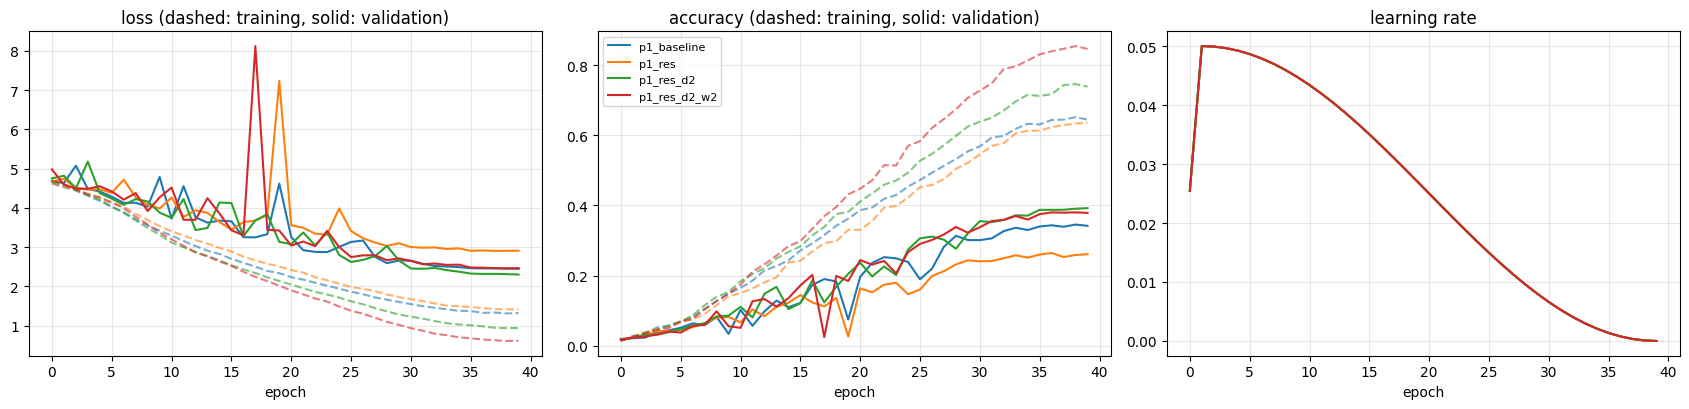

In [22]:
RUN_P1_CAPACITY = True

P1_CAPACITY = {
    "p1_res":       dict(P1_BASE, block="residual"),
    "p1_res_d2":    dict(P1_BASE, block="residual", depths=[2, 2, 2, 2]),
    "p1_res_d2_w2": dict(P1_BASE, block="residual", depths=[2, 2, 2, 2], widths=[64, 128, 256, 512]),
}
if RUN_P1_CAPACITY:
    for run_name, cfg in P1_CAPACITY.items():
        run_experiment(run_name, build_aircraftnet, cfg)

names = ["p1_baseline"] + list(P1_CAPACITY)
display(results_table(names, reference="p1_baseline"))
plot_runs(names)

> *Observations:* model selection is based on the validation accuracy (single seed, differences of 1–2 points are within noise).
> - **Residual blocks alone hurt** (`p1_res`, −8 points). With one block per stage, every block downsamples, so every skip connection is a strided 1×1 projection and never an identity: the network gets none of the benefits of residual learning, while the 1×1 stride-2 path only sees one pixel out of four. Skip connections pay off with deeper stages (`p1_res_d2`), where most shortcuts are identities.
> - **Depth helps**: `p1_res_d2` is the best model (39.2%), with training accuracy rising from 65% to 74%.
> - **Width increases the capacity but not the accuracy**: `p1_res_d2_w2` (11.2M parameters) fits the training set much better (84%), but validation accuracy does not improve (38.0%): capacity is no longer the bottleneck, and the generalization gap (46 points) is now the main problem.
> - **Instability persists in all models** while the LR is high (validation loss spikes up to 7–8), so the learning rate of 0.05 is likely too large; the curves become smooth only as the cosine schedule decays.
>
> Next step: regularization, on both the deeper and the wider network (the larger model may benefit more from it).

### P1.5 Regularization

The networks now have enough capacity; the goal is to reduce the generalization gap. Regularizers are first added
together to see how far they can go — their individual contribution is measured later, in the ablation study:
- `aug="strong"`: color jitter and random grayscale on top of random crops and flips;
- `label_smoothing=0.1`: targets are 0.9 for the correct class instead of 1, which discourages over-confident predictions;
- `dropout=0.3` before the classifier.

The same recipe is applied to the deeper (`d2`) and the wider (`d2_w2`) network; a third run uses a smaller learning rate
(0.02), to check whether it removes the instability observed so far.

[p1_d2_reg] already completed (published by simone): val acc 0.3192 | test acc 0.3144
[p1_d2w2_reg] already completed (published by simone): val acc 0.3990 | test acc 0.3996
[p1_d2w2_reg_lr002] already completed (published by simone): val acc 0.2880 | test acc 0.2763


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
p1_res_d2,2.822,40,39,0.739,0.392,0.378,9.837,Tesla T4,0.000,0.000
p1_res_d2_w2,11.203,40,36,0.840,0.380,0.384,11.230,Tesla T4,-0.012,0.006
p1_d2_reg,2.822,40,36,0.416,0.319,0.314,12.709,Tesla T4,-0.073,-0.064
p1_d2w2_reg,11.203,40,35,0.554,0.399,0.400,14.573,Tesla T4,0.007,0.022
p1_d2w2_reg_lr002,11.203,40,37,0.421,0.288,0.276,14.438,Tesla T4,-0.104,-0.102


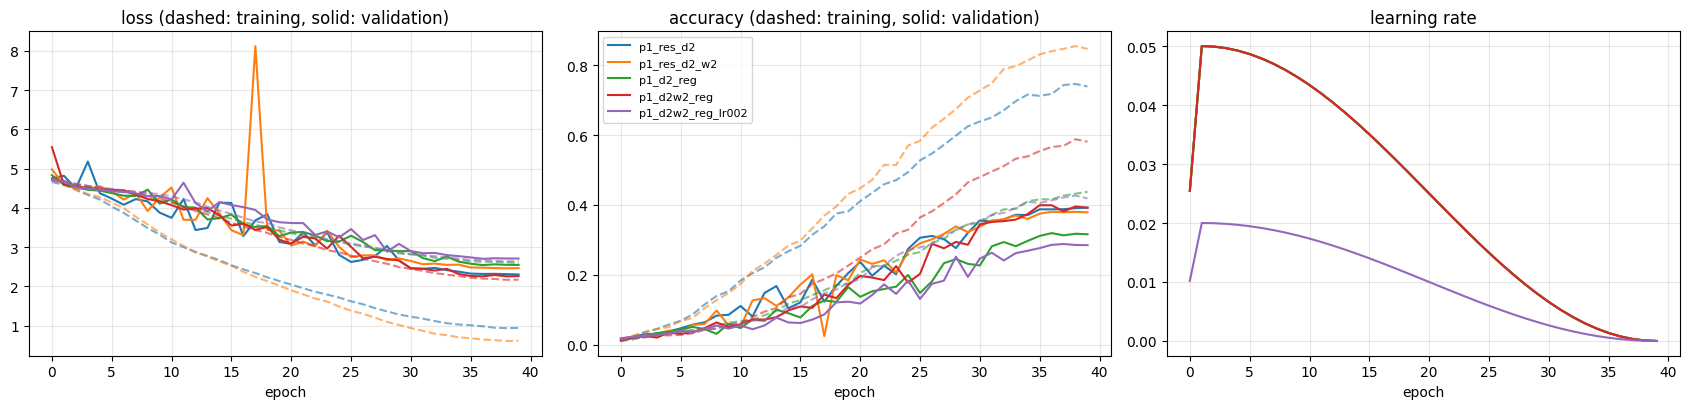

In [23]:
RUN_P1_REG = True

REG = {"aug": "strong", "label_smoothing": 0.1, "dropout": 0.3}
P1_REG = {
    "p1_d2_reg":         dict(P1_CAPACITY["p1_res_d2"], **REG),
    "p1_d2w2_reg":       dict(P1_CAPACITY["p1_res_d2_w2"], **REG),
    "p1_d2w2_reg_lr002": dict(P1_CAPACITY["p1_res_d2_w2"], **REG, lr=0.02),
}
if RUN_P1_REG:
    for run_name, cfg in P1_REG.items():
        run_experiment(run_name, build_aircraftnet, cfg)

names = ["p1_res_d2", "p1_res_d2_w2"] + list(P1_REG)
display(results_table(names, reference="p1_res_d2"))
plot_runs(names)

> *Observations:*
> - **Regularization pays off only with enough capacity.** On the wide network (`p1_d2w2_reg`, 11.2M) it gives the best model so far (39.9%) and shrinks the generalization gap from 46 to ≈16 points; on the smaller network (`p1_d2_reg`, 2.8M) it causes underfitting (training accuracy 42%) and lowers validation accuracy by 7 points.
> - **The instability disappears with regularization**: the wide regularized model has no validation-loss spikes even at LR 0.05. A plausible explanation is label smoothing, which prevents over-confident logits, so wrong predictions no longer produce huge losses.
> - **A smaller learning rate is not the solution**: with LR 0.02 the network learns more slowly and loses 11 points after 40 epochs.
> - **All regularized models are still improving at the end of training** (training accuracy < 60% and validation accuracy still rising), so 40 epochs are too few: the next step is a longer schedule.

### P1.6 Longer training and MixUp / CutMix

Regularized models learn more slowly, so we train for 100 epochs instead of 40:
- `p1_d2w2_reg_e100`: the best model so far, trained 2.5× longer;
- `p1_d2_reg_e100`: the smaller network, to check whether it catches up with a longer schedule;
- `p1_d2w2_reg_mix_e100`: the best model with MixUp (α = 0.2) or CutMix (α = 1), chosen at random for every batch:
  a stronger regularizer that also discourages relying on a single region of the image (e.g. the livery on the tail).

[p1_d2w2_reg_e100] already completed (published by simone): val acc 0.5902 | test acc 0.5836
[p1_d2_reg_e100] already completed (published by simone): val acc 0.5653 | test acc 0.5734
[p1_d2w2_reg_mix_e100] already completed (published by simone): val acc 0.5776 | test acc 0.5629


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
p1_d2w2_reg,11.203,40,35,0.554,0.399,0.400,14.573,Tesla T4,0.000,0.000
p1_d2w2_reg_e100,11.203,100,90,0.990,0.590,0.584,36.124,Tesla T4,0.191,0.184
p1_d2_reg_e100,2.822,100,93,0.934,0.565,0.573,32.709,Tesla T4,0.166,0.174
p1_d2w2_reg_mix_e100,11.203,100,92,0.706,0.578,0.563,36.070,Tesla T4,0.179,0.163


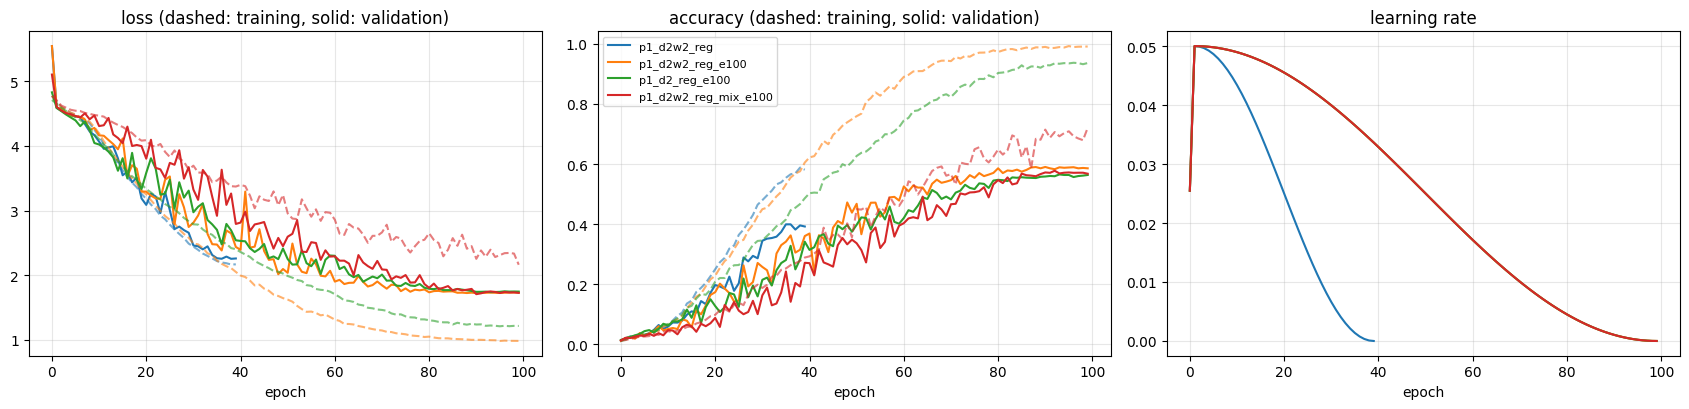

In [24]:
RUN_P1_LONG = True

P1_LONG = {
    "p1_d2w2_reg_e100":     dict(P1_REG["p1_d2w2_reg"], epochs=100),
    "p1_d2_reg_e100":       dict(P1_REG["p1_d2_reg"], epochs=100),
    "p1_d2w2_reg_mix_e100": dict(P1_REG["p1_d2w2_reg"], epochs=100, mixup_alpha=0.2, cutmix_alpha=1.0),
}
if RUN_P1_LONG:
    for run_name, cfg in P1_LONG.items():
        run_experiment(run_name, build_aircraftnet, cfg)

names = ["p1_d2w2_reg"] + list(P1_LONG)
display(results_table(names, reference="p1_d2w2_reg"))
plot_runs(names)

> *Observations:*
> - **Training longer is by far the most effective change**: with 100 epochs the wide regularized network reaches **59.0% validation / 58.4% test accuracy** (+19 points w.r.t. 40 epochs), above the 50% target. Its training accuracy reaches 99%, yet validation accuracy keeps improving until epoch ≈90: regularization lets the network fit the training set without memorizing it.
> - **The smaller network catches up** (56.5%, with 4× fewer parameters): the extra width is worth ≈2.5 points.
> - **MixUp / CutMix do not help within 100 epochs** (57.8%, −1.3 points, within noise): training accuracy stays at ≈70%, i.e. such a strong regularizer would need a longer schedule.
>
> We therefore fix `p1_d2w2_reg_e100` as the first final model of Part 1, analysed in P1.7 and refined in P1.8–P1.11.

### P1.7 First final model and ablation study

**First final model** (`p1_d2w2_reg_e100`): `AircraftNet` with residual blocks, 2 blocks per stage, widths 64–128–256–512
(11.2M parameters), batch normalization, dropout 0.3 before the classifier; rectangular 192×288 input with strong
augmentation; SGD with Nesterov momentum (LR 0.05, weight decay 5·10⁻⁴), cosine schedule with 2 warm-up epochs,
label smoothing 0.1, 100 epochs, batch size 64.

**Ablation study**: every run removes (or replaces) **one** component of the final model, everything else unchanged.
Some runs of the previous sections already differ from the final model in exactly one component and are reused.
A second run of the final model with a different seed estimates the run-to-run noise: differences smaller than that
should not be considered significant.

In [25]:
def ablation_report(final_name, ablation, reused, title="Ablation study"):
    """Table + bar chart of the Δ validation accuracy of every ablation w.r.t. the final model.
    ablation: {run name: (description, config)}; reused: {run name: description}. Only completed runs are shown."""
    done = is_done
    if not done(final_name):
        print(f"Final model '{final_name}' not available: ablation report skipped")
        return
    rows = [(final_name, "final model")] + [(n, d) for n, (d, _) in ablation.items() if done(n)] + \
           [(n, d) for n, d in reused.items() if done(n)]
    names, labels = [n for n, _ in rows], [d for _, d in rows]
    display(results_table(names, labels, reference=names[0]))
    ref = _load(names[0])[2]["best_val_acc"]
    deltas = [(_load(n)[2]["best_val_acc"] - ref) * 100 for n in names[1:]]
    order = np.argsort(deltas)
    plt.figure(figsize=(8, 0.45 * len(deltas) + 1))
    plt.barh([labels[1:][i] for i in order], [deltas[i] for i in order],
             color=["tab:red" if deltas[i] < 0 else "tab:green" for i in order])
    plt.axvline(0, color="black", lw=0.8)
    plt.xlabel("Δ validation accuracy w.r.t. the final model (points)")
    plt.title(title)
    plt.tight_layout()
    plt.show()


P1_FINAL_NAME = "p1_d2w2_reg_e100"
P1_FINAL = P1_LONG[P1_FINAL_NAME]

RUN_P1_ABLATION = True

P1_ABLATION = {  # run name: (description, config); ordered by expected informativeness
    "p1_abl_seed1":    ("final model, different seed",       dict(P1_FINAL, seed=SEED + 1)),
    "p1_abl_noaug":    ("no data augmentation",              dict(P1_FINAL, aug="none")),
    "p1_abl_plain":    ("plain blocks (no skip connections)", dict(P1_FINAL, block="plain")),
    "p1_abl_nobn":     ("no batch normalization",            dict(P1_FINAL, bn=False)),
    "p1_abl_nols":     ("no label smoothing",                dict(P1_FINAL, label_smoothing=0.0)),
    "p1_abl_nodrop":   ("no dropout",                        dict(P1_FINAL, dropout=0.0)),
    "p1_abl_crop":     ("square center crop, 224×224",       dict(P1_FINAL, resize_mode="crop", img_size=224)),
}
P1_REUSED = {  # runs of the previous sections that differ from the final model in one component only
    "p1_d2_reg_e100":       "half width (2.8M parameters)",
    "p1_d2w2_reg":          "40 epochs instead of 100",
    "p1_d2w2_reg_mix_e100": "+ MixUp / CutMix",
}

if RUN_P1_ABLATION:
    for run_name, (_, cfg) in P1_ABLATION.items():
        run_experiment(run_name, build_aircraftnet, cfg)

[p1_abl_seed1] already completed (published by simone): val acc 0.5908 | test acc 0.5710
[p1_abl_noaug] already completed (published by simone): val acc 0.2835 | test acc 0.2862
[p1_abl_plain] already completed (published by simone): val acc 0.6001 | test acc 0.5851
[p1_abl_nobn] already completed (published by simone): val acc 0.4515 | test acc 0.4407
[p1_abl_nols] already completed (published by simone): val acc 0.5719 | test acc 0.5677
[p1_abl_nodrop] already completed (published by simone): val acc 0.5728 | test acc 0.5704
[p1_abl_crop] already completed (published by simone): val acc 0.6235 | test acc 0.6178


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
final model,11.203,100,90,0.990,0.590,0.584,36.124,Tesla T4,0.000,0.000
"final model, different seed",11.203,100,97,0.987,0.591,0.571,8.957,NVIDIA L4,0.001,-0.013
no data augmentation,11.203,100,82,1.000,0.284,0.286,8.559,NVIDIA L4,-0.307,-0.297
plain blocks (no skip connections),11.027,100,93,0.972,0.600,0.585,8.173,NVIDIA L4,0.010,0.002
no batch normalization,11.198,100,93,0.760,0.452,0.441,8.414,NVIDIA L4,-0.139,-0.143
no label smoothing,11.203,100,95,0.974,0.572,0.568,8.976,NVIDIA L4,-0.018,-0.016
no dropout,11.203,100,99,0.993,0.573,0.570,9.009,NVIDIA L4,-0.017,-0.013
"square center crop, 224×224",11.203,100,97,0.976,0.623,0.618,7.956,NVIDIA L4,0.033,0.034
half width (2.8M parameters),2.822,100,93,0.934,0.565,0.573,32.709,Tesla T4,-0.025,-0.010


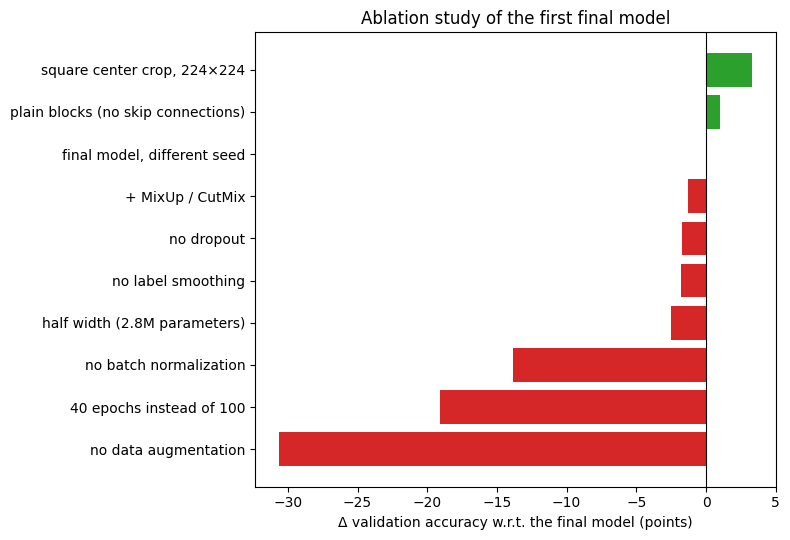

In [26]:
ablation_report(P1_FINAL_NAME, P1_ABLATION, P1_REUSED, title="Ablation study of the first final model")

> *Observations:* a second run of the final model with a different seed gives 59.1% vs 59.0% validation accuracy (1.3 points apart on the test set): differences below ≈1.5 points are within noise.
> - **Essential components**: data augmentation (−30.7 points: without it the network memorizes the training set, 100% training accuracy), the length of training (−19.1 with 40 epochs) and batch normalization (−13.9: without it even the training accuracy stops at 76%, so its main role here is to make optimization possible).
> - **Small contributions, just above the noise level**: half width (−2.5), label smoothing (−1.8), dropout (−1.7); adding MixUp/CutMix (−1.3) does not help.
> - **Skip connections are not needed** (+1.0, within noise): with batch normalization, an 18-layer plain network is trained just as well; residual connections become important for much deeper networks.
> - **The square center crop is better than the rectangular input (+3.3 points).** This contradicts our hypothesis, but the comparison mixes two factors: in crop mode the image is resized to a height of 256 px before cropping, in rect mode to 192 px, so the crop sees the aircraft at 1.33× higher resolution. It loses nose and tail, but it gains details on fuselage, engines and windows, which matter more in a fine-grained task. The next section separates the two factors.

### P1.8 Geometry or resolution?

`p1_rect256` uses the rectangular input at 256×384: the same scale as the center crop, but with the whole aircraft.
- if it beats the crop, keeping the whole aircraft *does* help and the first rectangular model was only too low-resolution;
- if it does not, what matters is the resolution on the central part of the aircraft.

The best of the three input geometries on the **validation** set becomes the reference model for the rest of Part 1 (P1.9–P1.11).

[p1_rect256] already completed (published by simone): val acc 0.6160 | test acc 0.6052


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
rectangular 192×288 (first final model),11.203,100,90,0.990,0.590,0.584,36.124,Tesla T4,0.000,0.000
square center crop 224×224,11.203,100,97,0.976,0.623,0.618,7.956,NVIDIA L4,0.033,0.034
rectangular 256×384,11.203,100,94,0.984,0.616,0.605,15.494,NVIDIA L4,0.026,0.022


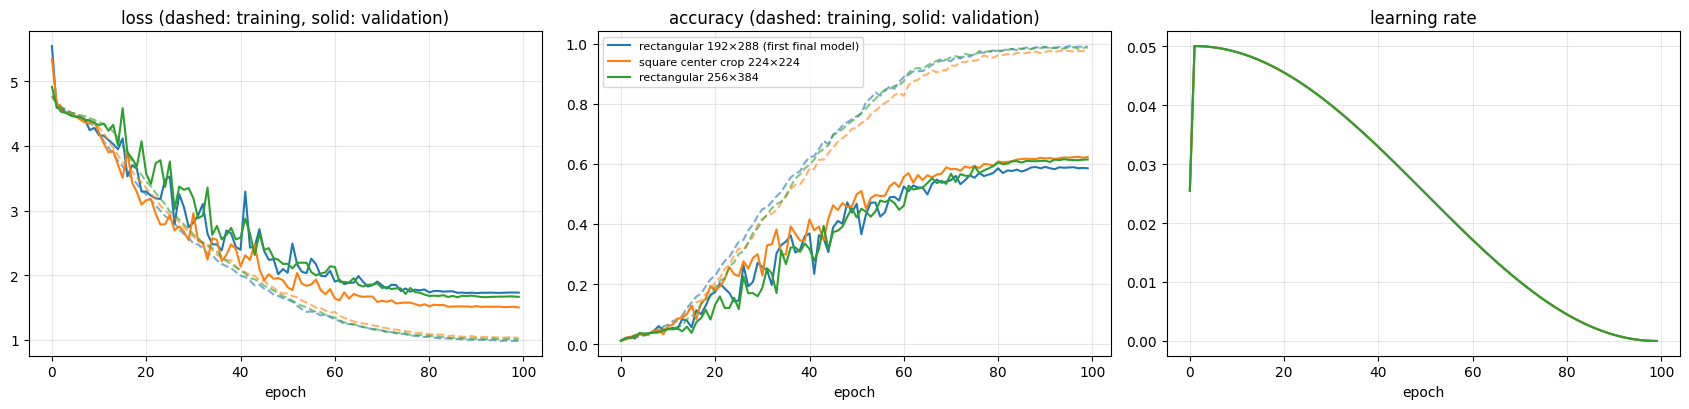

Reference model for P1.9–P1.11: p1_abl_crop (square center crop 224×224)


In [27]:
RUN_P1_GEOMETRY = True

P1_GEOMETRY = {  # run name: (description, config) — all identical except for the input geometry
    "p1_d2w2_reg_e100": ("rectangular 192×288 (first final model)", P1_FINAL),
    "p1_abl_crop":      ("square center crop 224×224",              P1_ABLATION["p1_abl_crop"][1]),
    "p1_rect256":       ("rectangular 256×384",                     dict(P1_FINAL, img_size=[256, 384])),
}
if RUN_P1_GEOMETRY:
    run_experiment("p1_rect256", build_aircraftnet, P1_GEOMETRY["p1_rect256"][1])

names = list(P1_GEOMETRY)
display(results_table(names, [d for d, _ in P1_GEOMETRY.values()], reference=names[0]))
plot_runs(names, [d for d, _ in P1_GEOMETRY.values()])

# Model selection on the validation accuracy only
P1_FINAL2_NAME = max((n for n in P1_GEOMETRY if is_done(n)), key=lambda n: _load(n)[2]["best_val_acc"])
P1_FINAL2 = P1_GEOMETRY[P1_FINAL2_NAME][1]
print(f"Reference model for P1.9–P1.11: {P1_FINAL2_NAME} ({P1_GEOMETRY[P1_FINAL2_NAME][0]})")

> *Observations:* at the same scale as the crop, the rectangular input (256×384, 61.6%) is 2.6 points better than at 192×288 (59.0%) and within noise of the square crop (62.3%). **The resolution, not the geometry, explains the gap found in P1.7**: keeping nose and tail brings no measurable benefit, while seeing the aircraft at a higher resolution does. On validation accuracy the square center crop is (marginally) the best option, and it is also about twice as fast (50k vs 98k input pixels): it becomes the reference model for the following sections (P1.9–P1.11).

### P1.9 Ablation study of the 224×224 model

The ablation study is repeated with respect to the model selected in P1.8, with the same components as in P1.7
plus the width, the length of training and MixUp/CutMix, which are now re-trained with the final input geometry.
The other two input geometries of P1.8 differ from it in one component only and are reused.

In [28]:
RUN_P1_ABLATION2 = True

F2 = P1_FINAL2
P1_ABLATION2 = {  # ordered by expected informativeness
    "p1_abl2_seed1":     ("final model, different seed",        dict(F2, seed=SEED + 1)),
    "p1_abl2_noaug":     ("no data augmentation",               dict(F2, aug="none")),
    "p1_abl2_plain":     ("plain blocks (no skip connections)", dict(F2, block="plain")),
    "p1_abl2_nobn":      ("no batch normalization",             dict(F2, bn=False)),
    "p1_abl2_nols":      ("no label smoothing",                 dict(F2, label_smoothing=0.0)),
    "p1_abl2_nodrop":    ("no dropout",                         dict(F2, dropout=0.0)),
    "p1_abl2_halfwidth": ("half width (2.8M parameters)",       dict(F2, widths=[32, 64, 128, 256])),
    "p1_abl2_e40":       ("40 epochs instead of 100",           dict(F2, epochs=40)),
    "p1_abl2_mix":       ("+ MixUp / CutMix",                   dict(F2, mixup_alpha=0.2, cutmix_alpha=1.0)),
}
P1_REUSED2 = {n: d for n, (d, _) in P1_GEOMETRY.items() if n != P1_FINAL2_NAME}

if RUN_P1_ABLATION2:
    for run_name, (_, cfg) in P1_ABLATION2.items():
        run_experiment(run_name, build_aircraftnet, cfg)

[p1_abl2_seed1] already completed (published by simone): val acc 0.6268 | test acc 0.6160
[p1_abl2_noaug] already completed (published by simone): val acc 0.3432 | test acc 0.3465
[p1_abl2_plain] already completed (published by simone): val acc 0.6217 | test acc 0.6301
[p1_abl2_nobn] already completed (published by simone): val acc 0.4752 | test acc 0.4656
[p1_abl2_nols] already completed (published by simone): val acc 0.6190 | test acc 0.6199
[p1_abl2_nodrop] already completed (published by simone): val acc 0.6190 | test acc 0.6031
[p1_abl2_halfwidth] already completed (published by simone): val acc 0.5998 | test acc 0.5980
[p1_abl2_e40] already completed (published by simone): val acc 0.4362 | test acc 0.4419
[p1_abl2_mix] already completed (published by simone): val acc 0.6061 | test acc 0.5890


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
final model,11.203,100,97,0.976,0.623,0.618,7.956,NVIDIA L4,0.000,0.000
"final model, different seed",11.203,100,97,0.977,0.627,0.616,7.834,NVIDIA L4,0.003,-0.002
no data augmentation,11.203,100,97,1.000,0.343,0.347,7.380,NVIDIA L4,-0.280,-0.271
plain blocks (no skip connections),11.027,100,95,0.959,0.622,0.630,7.074,NVIDIA L4,-0.002,0.012
no batch normalization,11.198,100,97,0.671,0.475,0.466,7.253,NVIDIA L4,-0.148,-0.152
no label smoothing,11.203,100,96,0.961,0.619,0.620,7.820,NVIDIA L4,-0.005,0.002
no dropout,11.203,100,92,0.989,0.619,0.603,7.816,NVIDIA L4,-0.005,-0.015
half width (2.8M parameters),2.822,100,96,0.913,0.600,0.598,6.112,NVIDIA L4,-0.024,-0.020
40 epochs instead of 100,11.203,40,38,0.543,0.436,0.442,3.201,NVIDIA L4,-0.187,-0.176


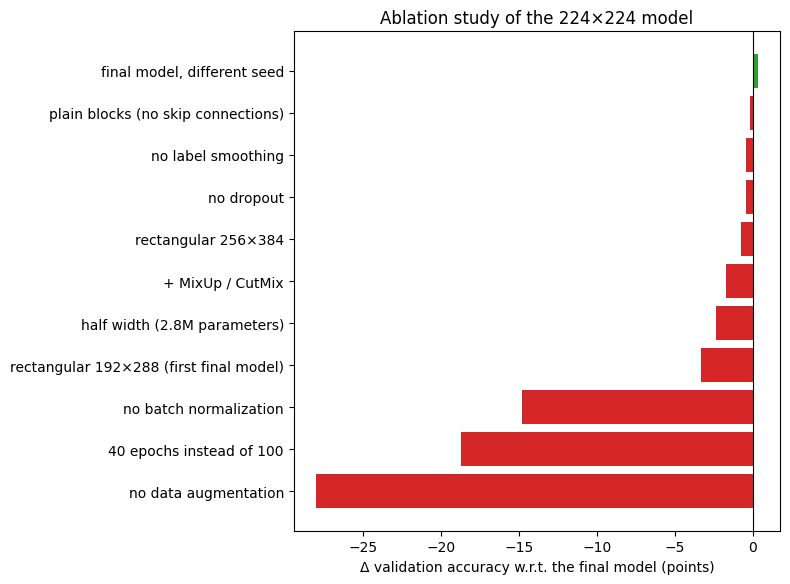

In [29]:
ablation_report(P1_FINAL2_NAME, P1_ABLATION2, P1_REUSED2, title="Ablation study of the 224×224 model")

> *Observations:* the 224×224 model reaches **62.3% validation and 61.8% test accuracy**; the run with a different seed (62.7% / 61.6%) confirms that differences below ≈1 point are noise.
> - **Essential components**: data augmentation (−28.0 points: without it the network memorizes the training set), training length (−18.7 with 40 epochs) and batch normalization (−14.8: without it even the training accuracy stops at 67%, so its role is mainly to make optimization possible).
> - **Moderate effect**: halving the width costs 2.4 points (4× fewer parameters), while adding MixUp/CutMix hurts (−1.7), because such strong regularization would need a longer schedule (training accuracy stays at 71%).
> - **No measurable effect**: skip connections (−0.2), label smoothing (−0.5), dropout (−0.5) and the whole-aircraft rectangular input (−0.8). With strong augmentation and a long schedule, augmentation is the dominant regularizer and the others become redundant; similarly, an 18-layer network with batch normalization is trained just as well without skip connections, which pay off only in much deeper networks. The model could therefore be simplified without loss of accuracy.
> - The same three components are essential as in the ablation of the first final model (P1.7), which makes these conclusions robust.

### P1.10 Input resolution

The ablation studies show that the input pipeline matters more than any architectural choice, and P1.8 showed that,
within it, what matters most is the resolution: the details that separate aircraft variants are small. We therefore train
the model of P1.9 at 336×336 and 448×448, with the same crop ratio (short side 384 and 512 before the center crop).
The network is fully convolutional up to the global average pooling, so the number of parameters does not change;
the cost per epoch grows ≈2.25× and ≈4×.

#### 336×336

[p1_final_336] already completed (published by francesco): val acc 0.6718 | test acc 0.6628


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
224×224 (P1.9),11.203,100,97,0.976,0.623,0.618,7.956,NVIDIA L4,0.000,0.000
336×336,11.203,100,96,0.975,0.672,0.663,17.807,NVIDIA L4,0.048,0.045


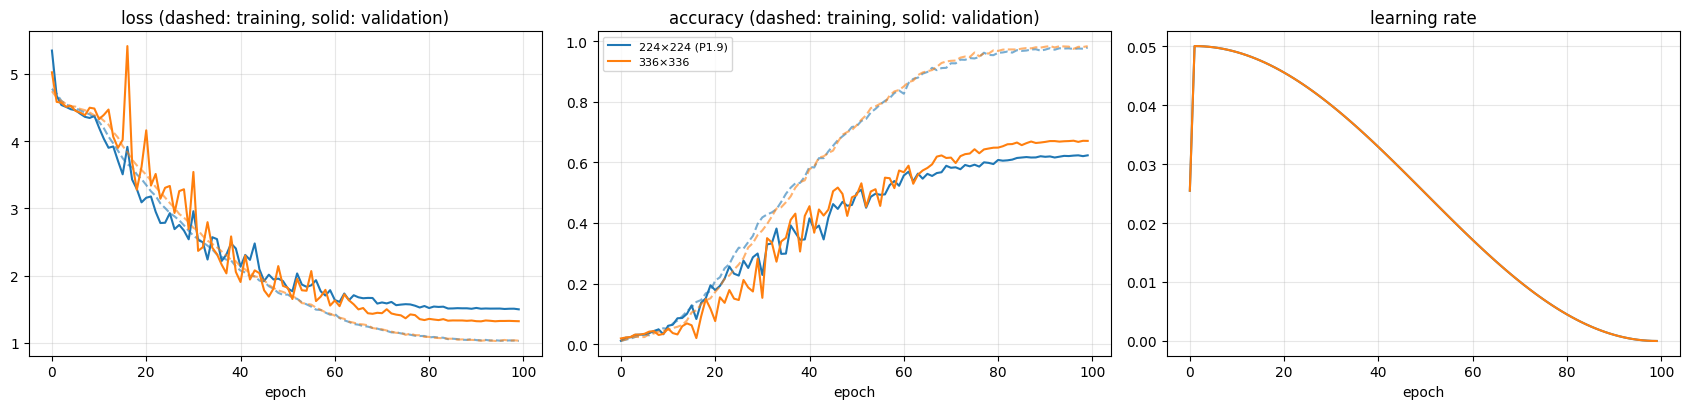

In [30]:
RUN_B1 = True

B1 = {"p1_final_336": ("336×336", dict(P1_FINAL2, img_size=336, short_side=384))}
if RUN_B1:
    for run_name, (_, cfg) in B1.items():
        run_experiment(run_name, build_aircraftnet, cfg)

names = [P1_FINAL2_NAME] + list(B1)
labels = ["224×224 (P1.9)"] + [d for d, _ in B1.values()]
display(results_table(names, labels, reference=P1_FINAL2_NAME))
plot_runs(names, labels)

> *Observations:* training at 336×336 improves Part 1 by **+4.8 validation / +4.5 test points** (67.2% / 66.3%), the largest gain after the ones measured in the ablation study, with the same number of parameters. The start is slightly slower and noisier (a validation-loss spike around epoch 16), but from epoch ≈65 the higher-resolution network is consistently better and its validation loss settles lower (≈1.32 vs ≈1.50). Training accuracy is the same for the two runs (≈98%): the gain comes from better generalization, not from fitting the training set better. The cost grows ≈2.2× (18 vs 8 minutes on an L4).

#### 448×448

Since 336×336 gave almost 5 points, we check whether the trend continues at 448×448 (short side 512 before the center
crop). The cost per epoch grows ≈4× w.r.t. 224×224.

[p1_final_448] already completed (published by francesco): val acc 0.6895 | test acc 0.6802


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
224×224 (P1.9),11.203,100,97,0.976,0.623,0.618,7.956,NVIDIA L4,0.000,0.000
336×336,11.203,100,96,0.975,0.672,0.663,17.807,NVIDIA L4,0.048,0.045
448×448,11.203,100,88,0.979,0.689,0.680,30.402,NVIDIA L4,0.066,0.062


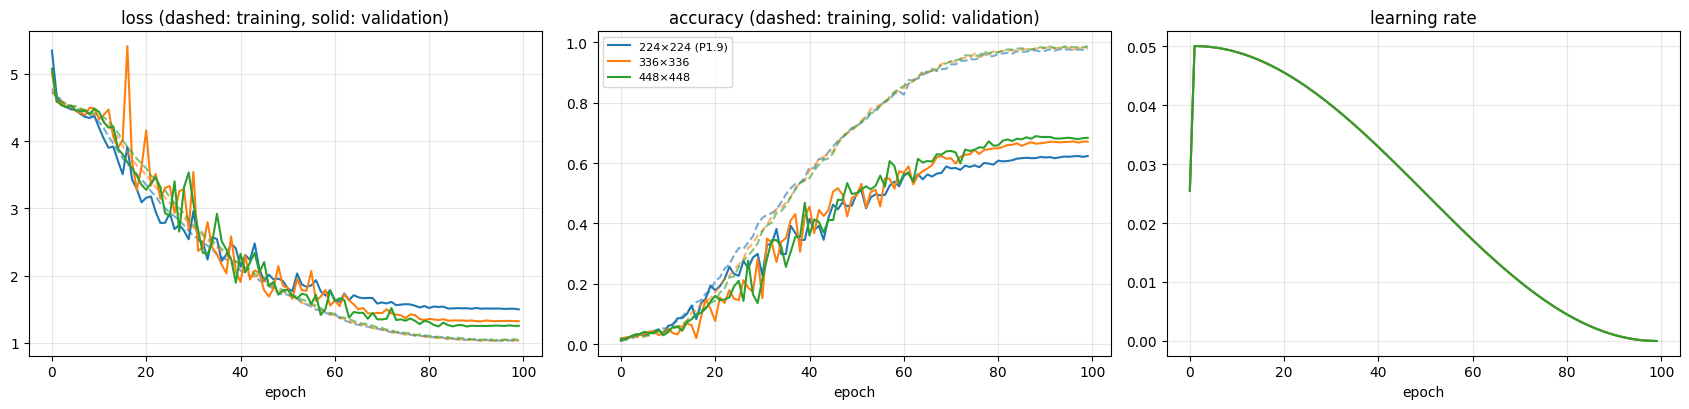

In [31]:
RUN_B2 = True

B2 = {"p1_final_448": ("448×448", dict(P1_FINAL2, img_size=448, short_side=512))}
if RUN_B2:
    for run_name, (_, cfg) in B2.items():
        run_experiment(run_name, build_aircraftnet, cfg)

names = [P1_FINAL2_NAME] + list(B1) + list(B2)
labels = ["224×224 (P1.9)"] + [d for d, _ in B1.values()] + [d for d, _ in B2.values()]
display(results_table(names, labels, reference=P1_FINAL2_NAME))
plot_runs(names, labels)

> *Observations:* the gain from resolution continues but slows down: 448×448 reaches **68.9% validation / 68.0% test accuracy**, +6.6 / +6.2 points w.r.t. 224×224, but only +1.8 / +1.7 w.r.t. 336×336 (just above noise), at almost twice the cost of 336×336 (30 vs 18 minutes on an L4, ≈4× the cost of 224×224). Training accuracy is again the same (≈98%), while the validation loss keeps decreasing with the resolution (≈1.50 → 1.32 → 1.25). The returns of resolution are diminishing: 336×336 offers the best trade-off between accuracy and cost, but 448×448 gives the highest accuracy and becomes the final model of Part 1.
>
> **Why we stop at 448×448.** The gain has dropped from +4.8 to +1.8 points, close to the ≈1-point run-to-run noise, while the cost keeps growing with the number of pixels: a run at 512×512 would take ≈40 minutes on an L4 (≈5× the cost of 224×224), and the final model must also be re-trained once for every component of its ablation study (P1.11). A further gain, if any, would most likely be within noise; the fine-tuning experiments of Part 2B, where 512×512 brings no improvement over 448×448, are consistent with this choice.

### P1.11 Final model and ablation study

**Final model of Part 1** (`p1_final_448`): `AircraftNet` with residual blocks, 2 blocks per stage, widths 64–128–256–512
(11.2M parameters), batch normalization, dropout 0.3 before the classifier; 448×448 center-crop input with strong
augmentation; SGD with Nesterov momentum (LR 0.05, weight decay 5·10⁻⁴), cosine schedule with 2 warm-up epochs,
label smoothing 0.1, 100 epochs, batch size 64.

The ablation study of P1.9 is repeated on this model: every run removes one component, everything else unchanged.
The width and MixUp/CutMix, whose effect was already measured twice with consistent results (P1.7, P1.9), are not
repeated, to save computation.
The 224×224 and 336×336 runs of P1.10 differ from it only in the input resolution and are reused.

[p1_abl448_seed1] already completed (published by simone): val acc 0.6907 | test acc 0.6925
[p1_abl448_noaug] already completed (published by simone): val acc 0.4557 | test acc 0.4551
[p1_abl448_plain] already completed (published by simone): val acc 0.6958 | test acc 0.6943
[p1_abl448_nobn] already completed (published by simone): val acc 0.4899 | test acc 0.4938
[p1_abl448_nols] already completed (published by simone): val acc 0.6787 | test acc 0.6835
[p1_abl448_nodrop] already completed (published by simone): val acc 0.6892 | test acc 0.6829
[p1_abl448_e40] already completed (published by simone): val acc 0.3969 | test acc 0.4071


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
final model,11.203,100,88,0.979,0.689,0.680,30.402,NVIDIA L4,0.000,0.000
"final model, different seed",11.203,100,94,0.986,0.691,0.692,25.499,NVIDIA A100-SXM4-80GB,0.001,0.012
no data augmentation,11.203,100,90,1.000,0.456,0.455,19.254,NVIDIA A100-SXM4-80GB,-0.234,-0.225
plain blocks (no skip connections),11.027,100,87,0.981,0.696,0.694,25.485,NVIDIA A100-SXM4-80GB,0.006,0.014
no batch normalization,11.198,100,94,0.616,0.490,0.494,24.793,NVIDIA A100-SXM4-80GB,-0.200,-0.186
no label smoothing,11.203,100,98,0.972,0.679,0.683,24.579,NVIDIA A100-SXM4-80GB,-0.011,0.003
no dropout,11.203,100,90,0.993,0.689,0.683,24.575,NVIDIA A100-SXM4-80GB,-0.000,0.003
40 epochs instead of 100,11.203,40,38,0.458,0.397,0.407,9.842,NVIDIA A100-SXM4-80GB,-0.293,-0.273
224×224 input,11.203,100,97,0.976,0.623,0.618,7.956,NVIDIA L4,-0.066,-0.062


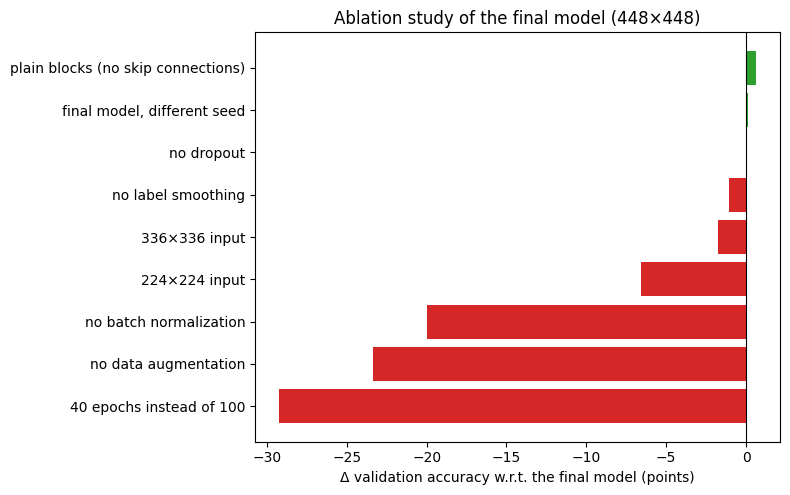

In [32]:
RUN_ABL448 = True

P1_448_NAME = "p1_final_448"
P1_448 = B2[P1_448_NAME][1]
ABL448 = {  # ordered by expected informativeness
    "p1_abl448_seed1":  ("final model, different seed",        dict(P1_448, seed=SEED + 1)),
    "p1_abl448_noaug":  ("no data augmentation",               dict(P1_448, aug="none")),
    "p1_abl448_plain":  ("plain blocks (no skip connections)", dict(P1_448, block="plain")),
    "p1_abl448_nobn":   ("no batch normalization",             dict(P1_448, bn=False)),
    "p1_abl448_nols":   ("no label smoothing",                 dict(P1_448, label_smoothing=0.0)),
    "p1_abl448_nodrop": ("no dropout",                         dict(P1_448, dropout=0.0)),
    "p1_abl448_e40":    ("40 epochs instead of 100",           dict(P1_448, epochs=40)),
}
REUSED448 = {P1_FINAL2_NAME: "224×224 input", "p1_final_336": "336×336 input"}

if RUN_ABL448:
    for run_name, (_, cfg) in ABL448.items():
        run_experiment(run_name, build_aircraftnet, cfg)

ablation_report(P1_448_NAME, ABL448, REUSED448, title="Ablation study of the final model (448×448)")

> *Observations:* the final model reaches **68.9% validation and 68.0% test accuracy**; the run with a different seed (69.1% / 69.2%) confirms that differences up to ≈1 point are noise.
> - **Essential components**: the length of training (−29.3 points with 40 epochs, when the training accuracy is still at 46%), data augmentation (−23.4: without it the network memorizes the training set, 100% training accuracy) and batch normalization (−20.0: without it even the training accuracy stops at 62%, so its role is mainly to make optimization possible). Compared with 224×224 (P1.9), the length of training and batch normalization matter even more — a larger input takes longer to learn — while removing augmentation costs a bit less (−23.4 vs −28.0).
> - **Input resolution**: 224×224 costs 6.6 points and 336×336 1.8 points (P1.10).
> - **No measurable effect**: skip connections (+0.6), label smoothing (−1.1), dropout (0.0). As at 224×224, with strong augmentation and a long schedule the other regularizers become redundant, and an 18-layer network with batch normalization is trained just as well without skip connections, which pay off only in much deeper networks. The final model could therefore be simplified without loss of accuracy.
> - The same three components are essential, and the same three have at most a small effect (below 2 points), in all three ablation studies (P1.7, P1.9, P1.11), which makes these conclusions robust.

## Part 2: fine-tune an existing network

Your goal is to fine-tune a pretrained ResNet-18 model on `FGVCAircraft`. Use the implementation provided by PyTorch, i.e. the opposite of part 1. Specifically, use the PyTorch ResNet-18 model pretrained on ImageNet-1K (V1). Divide your fine-tuning into two parts:

2A. First, fine-tune the ResNet-18 with the same training hyperparameters you used for your best model in part 1.

2B. Then, tweak the training hyperparameters to increase the accuracy on the test split. Justify your choices by analyzing the training plots and/or citing sources that guided you in your decisions — papers, blog posts, YouTube videos, or whatever else you may find useful. You should consider yourselves satisfied once you obtain a classification accuracy on the test split of ~70%.

### 2A. Fine-tuning with the hyperparameters of Part 1

The pretrained ResNet-18 (ImageNet-1K V1 weights) keeps all its layers; only the final fully connected layer is replaced
by a new one with 100 outputs. The model is trained with **the same training hyperparameters of the final model of Part 1,
including its input resolution**: 448×448 center crop with strong augmentation, SGD with Nesterov momentum, LR 0.05,
weight decay 5·10⁻⁴, cosine schedule with 2 warm-up epochs, label smoothing 0.1, batch size 64, 100 epochs. The dropout
(0.3) before the classifier is also kept, as part of the same training recipe; the architectural choices of Part 1
(widths, depths, blocks) obviously do not apply.

Inputs were normalized with the ImageNet statistics since Part 1, so the pretrained network receives inputs from the
distribution it was trained on without any change to the pipeline.

{
 "seed": 42,
 "img_size": 448,
 "resize_mode": "crop",
 "aug": "strong",
 "rrc_scale": [
  0.35,
  1.0
 ],
 "batch_size": 64,
 "epochs": 100,
 "optimizer": "sgd",
 "lr": 0.05,
 "wd": 0.0005,
 "scheduler": "cosine",
 "warmup_epochs": 2,
 "label_smoothing": 0.1,
 "mixup_alpha": 0.0,
 "cutmix_alpha": 0.0,
 "dropout": 0.3,
 "short_side": 512,
 "model": "resnet18_imagenet1k_v1"
}
[p2a_resnet18_448] already completed (published by simone): val acc 0.8050 | test acc 0.8182


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
"Part 1, final model (448×448, from scratch)",11.203,100,88,0.979,0.689,0.680,30.402,NVIDIA L4,0.000,0.000
"2A: ResNet-18 pretrained (448×448), recipe of Part 1",11.228,100,88,1.000,0.805,0.818,32.499,NVIDIA L4,0.116,0.138


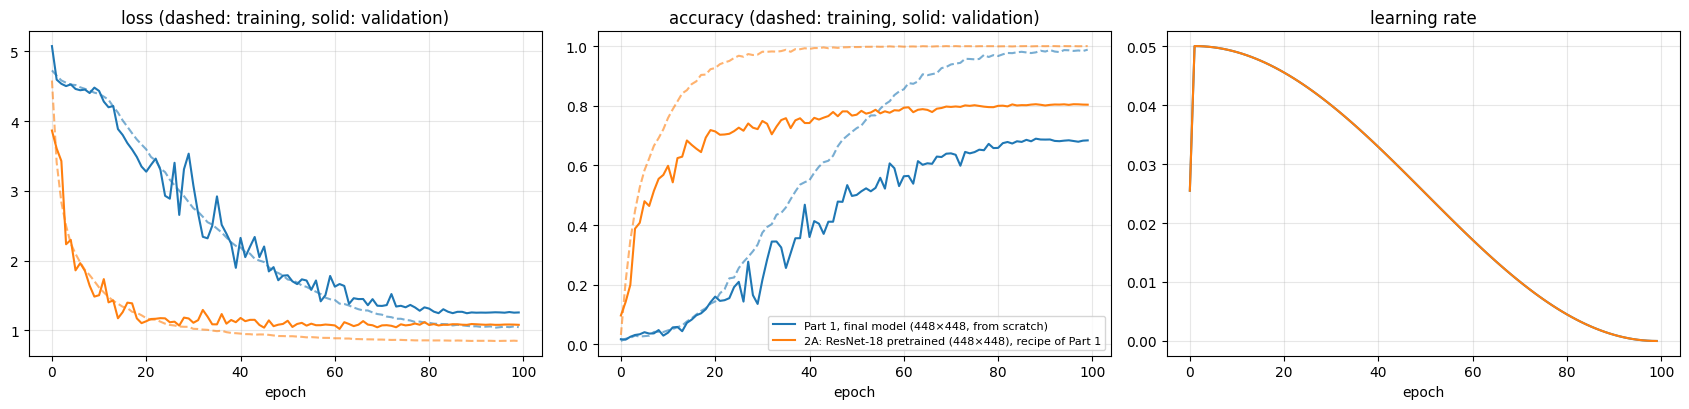

In [33]:
from torchvision.models import resnet18, ResNet18_Weights


def build_resnet18(cfg):
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Sequential(nn.Dropout(cfg.get("dropout", 0.0)), nn.Linear(model.fc.in_features, num_classes))
    return model


def reuse_run(src, dst, cfg):
    """If the completed run `src` has exactly the configuration `cfg`, it is copied as `dst` instead of being re-trained
    (the same configuration had already been trained under another name during the experimentation)."""
    if is_done(dst) or not is_done(src):
        return
    saved = load_json(f"{find_run_dir(src)}/config.json")
    norm = json.loads(json.dumps(cfg))
    if {k: saved.get(k) for k in norm} == norm:
        shutil.copytree(find_run_dir(src), run_dir_of(dst))
        print(f"[{dst}] same configuration as '{src}': copied, not re-trained")


def resnet_param_groups(model, cfg):
    """Classifier (fc) with the base LR, pretrained backbone with LR × backbone_lr_mult (discriminative fine-tuning).
    The classifier group comes first, so the plotted LR is the one of the classifier, as in the other runs."""
    head = list(model.fc.parameters())
    head_ids = {id(p) for p in head}
    backbone = [p for p in model.parameters() if id(p) not in head_ids]
    return [{"params": head, "lr": cfg["lr"]},
            {"params": backbone, "lr": cfg["lr"] * cfg.get("backbone_lr_mult", 1.0)}]


TRAINING_KEYS = ["seed", "img_size", "resize_mode", "aug", "rrc_scale", "batch_size", "epochs", "optimizer", "lr", "wd",
                 "scheduler", "warmup_epochs", "label_smoothing", "mixup_alpha", "cutmix_alpha", "dropout"]
# recipe of the final model of Part 1, including its input resolution
P2A = dict({k: P1_448[k] for k in TRAINING_KEYS}, short_side=P1_448["short_side"], model="resnet18_imagenet1k_v1")
P2A_NAME = "p2a_resnet18_448"
print(json.dumps(P2A, indent=1))

RUN_P2A = True
reuse_run("p2b_e100_448", P2A_NAME, P2A)
if RUN_P2A:
    run_experiment(P2A_NAME, build_resnet18, P2A, build_params=resnet_param_groups)

names = [P1_448_NAME, P2A_NAME]
labels = ["Part 1, final model (448×448, from scratch)", "2A: ResNet-18 pretrained (448×448), recipe of Part 1"]
display(results_table(names, labels, reference=P1_448_NAME))
plot_runs(names, labels)

> *Observations:*
> - **Pretraining is worth ≈12–14 points with the very same recipe**: 80.5% validation / 81.8% test accuracy, vs 68.9% / 68.0% for our network trained from scratch — well above the ≈70% target.
> - **Much faster convergence**: the pretrained network fits the training set completely (100%) around epoch 50, and its validation accuracy then improves only slowly until epoch ≈85. The recipe of Part 1 was designed for training from scratch, so some of its choices (the length of the schedule, the learning rate, the augmentation) may not be the best ones for fine-tuning: they are examined in 2B.

### 2B. Tuning the hyperparameters for fine-tuning

2A already uses the 448×448 input that worked best in Part 1. Starting from it, we tune, one at a time and selecting on
the validation accuracy, the hyperparameters that may still matter for fine-tuning:

1. **Length of training** — pretrained networks converge much faster than networks trained from scratch, so 100 epochs
   may be more than needed; if 50 epochs are enough, they also halve the cost of the following experiments.
2. **Learning rate** — pretrained layers already encode useful features and are often adapted with a smaller learning
   rate than the new classifier, which starts from random weights (*discriminative fine-tuning*, Howard & Ruder,
   *Universal Language Model Fine-tuning for Text Classification*, ACL 2018). The choice of the
   fine-tuning learning rate is studied in depth by Li et al., *Rethinking the Hyperparameters for Fine-tuning*,
   ICLR 2020. We compare a globally smaller (0.01) and larger (0.1) learning rate, and a 10× smaller one on the backbone only.
3. **Input resolution** — 2A inherits 448×448 from Part 1: we check both a higher (512×512) and lower resolutions
   (224×224 and 336×336).
4. **Stronger augmentation** — TrivialAugment (Müller & Hutter, ICCV 2021).

We did not repeat a fine-tuning run with a different seed: differences are judged against the run-to-run noise
measured in Part 1 (≈1 point, P1.9 and P1.11), assuming that it also holds for the fine-tuned network.

#### Length of training

[p2b_e50_448] already completed (published by francesco): val acc 0.8020 | test acc 0.8080


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
2A (100 epochs),11.228,100,88,1.000,0.805,0.818,32.499,NVIDIA L4,0.000,0.000
50 epochs,11.228,50,41,0.998,0.802,0.808,12.716,NVIDIA A100-SXM4-80GB,-0.003,-0.010


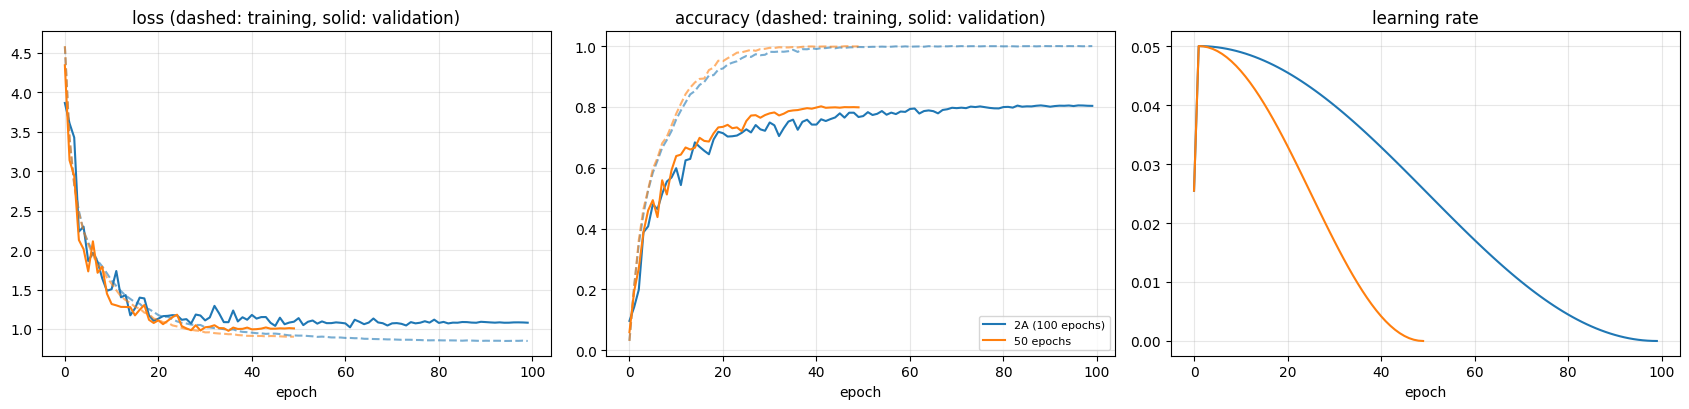

In [34]:
RUN_P2B_E50 = True

P2B_E50 = {"p2b_e50_448": ("50 epochs", dict(P2A, epochs=50))}
if RUN_P2B_E50:
    for run_name, (_, cfg) in P2B_E50.items():
        run_experiment(run_name, build_resnet18, cfg, build_params=resnet_param_groups)

names = [P2A_NAME] + list(P2B_E50)
labels = ["2A (100 epochs)"] + [d for d, _ in P2B_E50.values()]
display(results_table(names, labels, reference=P2A_NAME))
plot_runs(names, labels)

> *Observations:* 50 epochs give 80.2% validation / 80.8% test accuracy, vs 80.5% / 81.8% with 100 epochs (−0.3 / −1.0 points, within noise): with a pretrained network the second half of the schedule brings no significant gain. The following experiments therefore use 50 epochs and are compared with this run, which halves their cost.

#### Learning rate

[p2b_e50_448_lr001] already completed (published by simone): val acc 0.7591 | test acc 0.7729
[p2b_e50_448_lr01] already completed (published by simone): val acc 0.7861 | test acc 0.7909
[p2b_e50_448_difflr] already completed (published by simone): val acc 0.7582 | test acc 0.7663


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
"50 epochs, LR 0.05",11.228,50,41,0.998,0.802,0.808,12.716,NVIDIA A100-SXM4-80GB,0.000,0.000
LR 0.01,11.228,50,48,0.994,0.759,0.773,12.086,NVIDIA A100-SXM4-80GB,-0.043,-0.035
LR 0.1,11.228,50,46,0.996,0.786,0.791,12.107,NVIDIA A100-SXM4-80GB,-0.016,-0.017
LR 0.05 classifier / 0.005 backbone,11.228,50,35,0.981,0.758,0.766,12.086,NVIDIA A100-SXM4-80GB,-0.044,-0.042


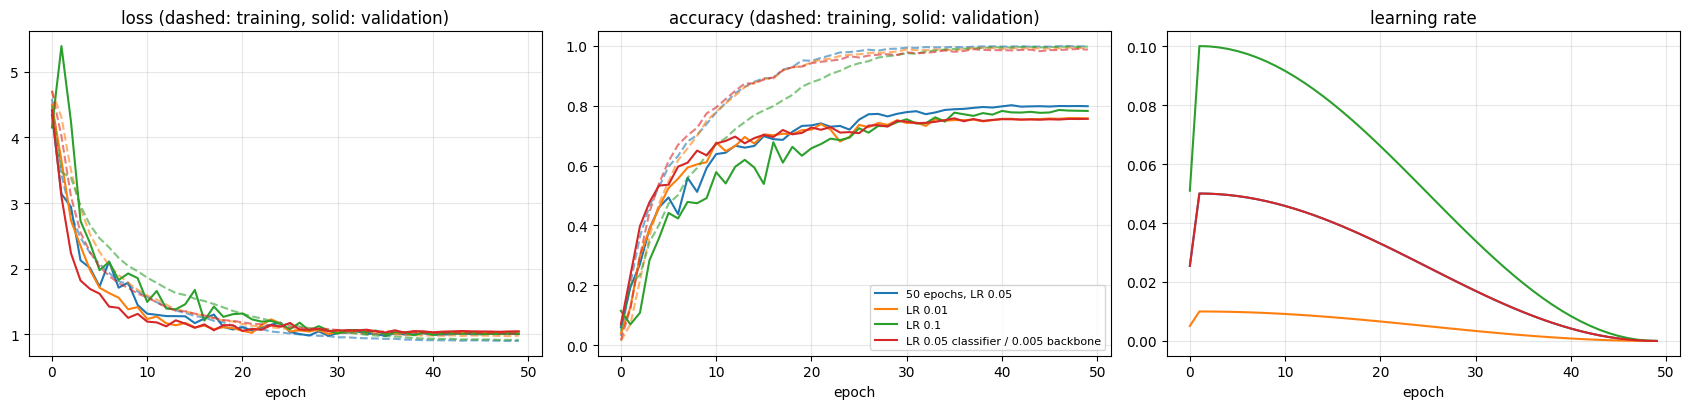

In [35]:
RUN_P2B_LR = True

E50 = P2B_E50["p2b_e50_448"][1]
P2B_LR = {
    "p2b_e50_448_lr001":  ("LR 0.01",                             dict(E50, lr=0.01)),
    "p2b_e50_448_lr01":   ("LR 0.1",                              dict(E50, lr=0.1)),
    "p2b_e50_448_difflr": ("LR 0.05 classifier / 0.005 backbone", dict(E50, backbone_lr_mult=0.1)),
}
if RUN_P2B_LR:
    for run_name, (_, cfg) in P2B_LR.items():
        run_experiment(run_name, build_resnet18, cfg, build_params=resnet_param_groups)

names = ["p2b_e50_448"] + list(P2B_LR)
labels = ["50 epochs, LR 0.05"] + [d for d, _ in P2B_LR.values()]
display(results_table(names, labels, reference="p2b_e50_448"))
plot_runs(names, labels)

> *Observations:* LR 0.05 remains the best choice: a globally smaller LR (0.01, −4.3 points) and a 10× smaller LR on the backbone (−4.4) clearly hurt, and a larger LR (0.1, −1.6) is slightly worse. The usual fine-tuning recipe — small learning rates to preserve the pretrained features — does not work here: the 100 aircraft variants are very far from the ImageNet classes, and the pretrained features must change substantially. Kornblith et al. (*Do Better ImageNet Models Transfer Better?*, CVPR 2019) observe that on FGVC-Aircraft fine-tuning has a smaller advantage over training from scratch than on most other datasets, and Li et al. (2020) report that the best fine-tuning hyperparameters depend on the similarity between source and target domain.

#### Input resolution

2A inherits the 448×448 input from Part 1, where resolution turned out to be the most important choice of the input
pipeline (P1.10). We check whether this also holds for the pretrained network, which was trained on ImageNet at 224×224:
- **higher**: 512×512 (short side 585 before the center crop), with 50 epochs. Unlike Part 1, where we stopped at
  448×448 because the gain had already dropped to +1.8 points, here a higher resolution is worth testing: the input
  resolution is the hyperparameter under study in this section, the gain of the pretrained network between 336×336 and
  448×448 is still large (table below), and a 50-epoch fine-tuning run is cheap (≈20 minutes on an L4) and does not
  have to be repeated for an ablation study;
- **lower**: 224×224 and 336×336. These configurations had already been trained during the experimentation with the same
  recipe (with both 50 and 100 epochs) and differ from the runs of this section only in the input resolution, as the cell
  below verifies on their saved configurations, so no new training is needed.

[p2b_e50_512] already completed (published by francesco): val acc 0.7993 | test acc 0.8176
p2b_e50 vs p2b_e50_448: {'img_size': (224, 448), 'short_side': (None, 512)}
p2b_e50_336 vs p2b_e50_448: {'img_size': (336, 448), 'short_side': (384, 512)}
p2b_e50_512 vs p2b_e50_448: {'img_size': (512, 448), 'short_side': (585, 512)}


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
"50 epochs, 224×224",11.228,50,35,0.984,0.708,0.710,17.085,Tesla T4,-0.094,-0.098
"50 epochs, 336×336",11.228,50,42,0.995,0.756,0.774,7.354,NVIDIA A100-SXM4-80GB,-0.046,-0.034
"50 epochs, 448×448",11.228,50,41,0.998,0.802,0.808,12.716,NVIDIA A100-SXM4-80GB,0.000,0.000
"50 epochs, 512×512",11.228,50,49,0.996,0.799,0.818,21.164,NVIDIA L4,-0.003,0.010


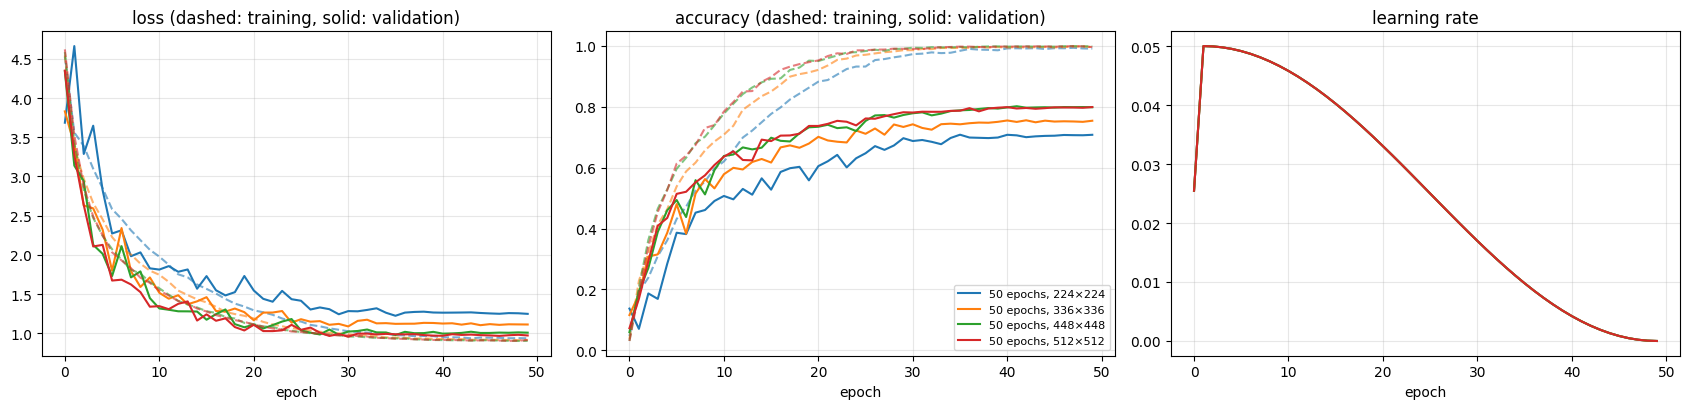

p2a_resnet18 vs p2a_resnet18_448: {'img_size': (224, 448), 'short_side': (None, 512)}


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
"100 epochs, 224×224",11.228,100,85,0.997,0.720,0.725,8.205,NVIDIA L4,-0.085,-0.094
"100 epochs, 448×448 (2A)",11.228,100,88,1.000,0.805,0.818,32.499,NVIDIA L4,0.000,0.000


In [36]:
RUN_C1 = True

C1 = {"p2b_e50_512": ("50 epochs, 512×512", dict(E50, img_size=512, short_side=585))}
if RUN_C1:
    for run_name, (_, cfg) in C1.items():
        run_experiment(run_name, build_resnet18, cfg, build_params=resnet_param_groups)

META = {"author", "gpu", "n_params", "n_trainable"}


def config_diff(a, b):
    """Keys whose value differs between the saved configurations of runs a and b (metadata excluded)."""
    ca, cb = (load_json(f"{find_run_dir(n)}/config.json") for n in (a, b))
    return {k: (ca.get(k), cb.get(k)) for k in sorted((set(ca) | set(cb)) - META) if ca.get(k) != cb.get(k)}


# 50 epochs: 224 -> 336 -> 448 -> 512
RES_50 = {"p2b_e50": "50 epochs, 224×224", "p2b_e50_336": "50 epochs, 336×336",
          "p2b_e50_448": "50 epochs, 448×448", "p2b_e50_512": "50 epochs, 512×512"}
names = [n for n in RES_50 if is_done(n)]
for n in names:
    if n != "p2b_e50_448":
        print(f"{n} vs p2b_e50_448: {config_diff(n, 'p2b_e50_448')}")
display(results_table(names, [RES_50[n] for n in names], reference="p2b_e50_448"))
plot_runs(names, [RES_50[n] for n in names])

# 100 epochs (the full recipe of Part 1): 224 vs 448 (2A)
RES_100 = {"p2a_resnet18": "100 epochs, 224×224", P2A_NAME: "100 epochs, 448×448 (2A)"}
print(f"p2a_resnet18 vs {P2A_NAME}: {config_diff('p2a_resnet18', P2A_NAME)}")
display(results_table(list(RES_100), list(RES_100.values()), reference=P2A_NAME))

> *Observations:* the input resolution is the hyperparameter that matters most for fine-tuning as well. With 50 epochs, validation accuracy grows from 70.8% at 224×224 to 75.6% at 336×336 and 80.2% at 448×448 (test: 71.0% → 77.4% → 80.8%), and then stops: 512×512 gives 79.9% (−0.3 points, within noise) at a higher cost. With the full 100-epoch recipe of Part 1 the same comparison gives 72.0% / 72.5% at 224×224 vs 80.5% / 81.8% at 448×448 (2A): **+8.5 / +9.4 points**. This is the same trend found in Part 1 (P1.10), and it explains why 2A, which inherits the 448×448 input from Part 1, is already a strong starting point: at the native resolution of the pretrained network (224×224) the same recipe would lose ≈9 points.

#### Stronger augmentation: TrivialAugment

Data augmentation is one of the two most important components of Part 1 (−23 to −31 points without it), so a stronger augmentation
may still help. **TrivialAugment** (Müller & Hutter, *TrivialAugment: Tuning-free Yet State-of-the-Art Data Augmentation*,
ICCV 2021) applies to every image one operation chosen at random from a fixed list (rotation, shear, translation, color,
contrast, sharpness, posterization, …) with a random strength, and needs no tuning. It replaces the color jitter and the
random grayscale of our `"strong"` augmentation (random crops and flips are kept). Since a stronger augmentation may need
a longer schedule, it is tested with both 50 and 100 epochs.

[p2b_e50_448_trivial] already completed (published by francesco): val acc 0.8050 | test acc 0.8143
[p2b_e100_448_trivial] already completed (published by simone): val acc 0.8113 | test acc 0.8284


,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
"50 epochs, strong augmentation",11.228,50,41,0.998,0.802,0.808,12.716,NVIDIA A100-SXM4-80GB,0.000,0.000
"50 epochs, TrivialAugment",11.228,50,46,0.946,0.805,0.814,15.895,NVIDIA L4,0.003,0.006
"100 epochs, strong augmentation (2A)",11.228,100,88,1.000,0.805,0.818,32.499,NVIDIA L4,0.003,0.010
"100 epochs, TrivialAugment",11.228,100,92,0.968,0.811,0.828,22.874,NVIDIA A100-SXM4-80GB,0.009,0.020


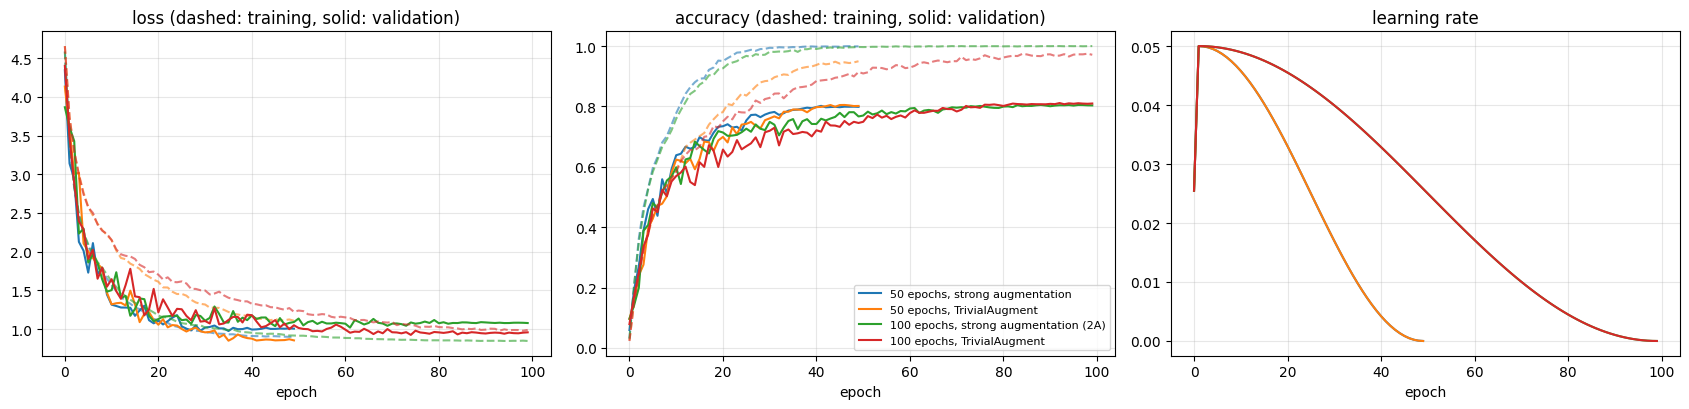

In [37]:
RUN_C2 = True

C2 = {
    "p2b_e50_448_trivial":  ("50 epochs, TrivialAugment",  dict(E50, aug="trivial")),
    "p2b_e100_448_trivial": ("100 epochs, TrivialAugment", dict(P2A, aug="trivial")),
}
if RUN_C2:
    for run_name, (_, cfg) in C2.items():
        run_experiment(run_name, build_resnet18, cfg, build_params=resnet_param_groups)

names = ["p2b_e50_448", "p2b_e50_448_trivial", P2A_NAME, "p2b_e100_448_trivial"]
labels = ["50 epochs, strong augmentation", "50 epochs, TrivialAugment",
          "100 epochs, strong augmentation (2A)", "100 epochs, TrivialAugment"]
display(results_table(names, labels, reference="p2b_e50_448"))
plot_runs(names, labels)

> *Observations:* TrivialAugment changes the training dynamics more than the accuracy. With 50 epochs it is within noise (+0.3 / +0.6 points); with 100 epochs it gives the best validation accuracy of all the runs (81.1%, +0.6 w.r.t. 2A) and 82.8% test accuracy (+1.0), a gain at the level of the run-to-run noise. Training accuracy stays below 100% (95% with 50 epochs, 97% with 100): the stronger augmentation reduces overfitting and, being a stronger regularizer, it profits from the longer schedule.

### 2B. Final model

The final model of 2B is the 2B variant with the best validation accuracy; if no variant improves on 2A beyond the noise,
this is stated explicitly.

In [38]:
P2B_CONFIGS = {**P2B_E50, **P2B_LR, **C1, **C2}
P2B_FINAL_NAME = max((n for n in P2B_CONFIGS if is_done(n)), key=lambda n: _load(n)[2]["best_val_acc"])

names = [P1_448_NAME, P2A_NAME, P2B_FINAL_NAME]
labels = ["Part 1: our network (448×448)", "2A: ResNet-18 (448×448), recipe of Part 1",
          f"2B: ResNet-18, {P2B_CONFIGS[P2B_FINAL_NAME][0]}"]
display(results_table(names, labels, reference=P2A_NAME))

,params (M),epochs,best epoch,train acc @best,val acc,test acc,minutes,gpu,Δ val acc,Δ test acc
run,,,,,,,,,,
Part 1: our network (448×448),11.203,100,88,0.979,0.689,0.680,30.402,NVIDIA L4,-0.116,-0.138
"2A: ResNet-18 (448×448), recipe of Part 1",11.228,100,88,1.000,0.805,0.818,32.499,NVIDIA L4,0.000,0.000
"2B: ResNet-18, 100 epochs, TrivialAugment",11.228,100,92,0.968,0.811,0.828,22.874,NVIDIA A100-SXM4-80GB,0.006,0.010


> *Observations:* following our selection rule, the final model of 2B is the 100-epoch run with TrivialAugment: **81.1% validation / 82.8% test accuracy**, +0.6 / +1.0 points w.r.t. 2A. The gain is at the level of the run-to-run noise: with the input resolution — worth ≈9 points — already at 448×448 since 2A, none of the other tested hyperparameters (length of training, learning rate, resolution, augmentation) improves the fine-tuning significantly. The recipe inherited from Part 1 is therefore already close to the best one we could find for the fine-tuned network: the two choices that matter most here, a high input resolution and a learning rate large enough to adapt the pretrained features, were both already part of it.

### Training on train + validation (`trainval`)

All the choices of this notebook (architecture, regularization, schedule, resolution, learning rate) were made by comparing
models on the validation split, which therefore could not be used for training. Once the choices are fixed, the validation
split is no longer needed for selection, and the final configurations can be **re-trained on train + validation**
(`trainval`, 6667 images, ≈67 per class instead of ≈33). This is the standard protocol of FGVC-Aircraft: training on
`trainval` and evaluating on `test`.

- **No selection on the test set**: the hyperparameters are exactly the ones selected on the validation split, and the test
  split is evaluated once, at the end of training.
- **The model of the last epoch is kept**, since there is no validation split left to select the best epoch; with the
  train-only protocol the best epochs were anyway at the end of the schedule (epoch 88–97 out of 100).
- The number of epochs is unchanged, so every epoch has twice as many steps and every run costs twice as much.
- These results use a different protocol (twice the training data), so they are reported separately and not compared
  with the ablation studies or the other experiments.

Configurations re-trained on `trainval`:
- the final model of Part 1 (448×448);
- the final model of 2B (ResNet-18 fine-tuned at 448×448).

In [39]:
def make_trainval_loader(cfg, seed=SEED):
    """Training loader on train + validation: the two caches are concatenated (the images are not copied)."""
    short_side = cfg.get("short_side", SHORT_SIDE)
    h, w = input_hw(cfg)
    needed = int(round(h * 256 / 224)) if cfg.get("resize_mode", "crop") == "crop" else h
    if needed > short_side:
        raise ValueError(f"a {h}x{w} input needs images with short side >= {needed}: set short_side in the config")
    tr, va = get_cache("train", short_side), get_cache("val", short_side)
    cache = {"images": tr["images"] + va["images"], "labels": tr["labels"] + va["labels"],
             "format": tr.get("format", "raw")}
    ds = CachedDataset(cache, make_transforms(True, cfg))
    g = torch.Generator(); g.manual_seed(seed)
    nw = min(os.cpu_count(), MAX_WORKERS)
    return DataLoader(ds, batch_size=cfg.get("batch_size", 64), shuffle=True, drop_last=True, num_workers=nw,
                      pin_memory=torch.cuda.is_available(), persistent_workers=nw > 0, generator=g)


def run_trainval(name, build_model, cfg, build_params=None):
    """Trains `cfg` on train + validation for cfg["epochs"] epochs and evaluates the last-epoch model once on the test
    split. Saves config.json, history.json (training metrics only), last.pt (to resume after a disconnection),
    best.pt (here: the model of the last epoch, there is no validation to select on) and results.json."""
    run_dir = run_dir_of(name)
    cfg = json.loads(json.dumps(dict(cfg, protocol="trainval")))
    existing = find_run_dir(name)
    if existing:
        saved = {k: v for k, v in load_json(f"{existing}/config.json").items() if k in cfg}
        if saved != cfg:
            raise ValueError(f"'{name}' already exists in {existing} with a different config: use another name.")
        if os.path.exists(f"{existing}/results.json"):
            res = load_json(f"{existing}/results.json")
            print(f"[{name}] already completed: test acc {res['test_acc']:.4f}")
            return res
    if not ALLOW_TRAINING:
        print(f"[{name}] not available and ALLOW_TRAINING = False: skipped")
        return None

    os.makedirs(run_dir, exist_ok=True)
    fix_random(cfg.get("seed", SEED))
    model = build_model(cfg).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    save_json(dict(cfg, author=AUTHOR, gpu=GPU_NAME, n_params=n_params), f"{run_dir}/config.json")
    print(f"[{name}] {n_params / 1e6:.2f}M parameters on {GPU_NAME}, trained on train + validation")

    train_loader = make_trainval_loader(cfg, seed=cfg.get("seed", SEED))
    use_amp = cfg.get("amp", True) and device.type == "cuda"
    params = build_params(model, cfg) if build_params else model.parameters()
    optimizer = build_optimizer(params, cfg)
    scheduler = build_scheduler(optimizer, cfg, len(train_loader))
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg.get("label_smoothing", 0.0))
    batch_mix = build_batch_mix(cfg)

    history = {k: [] for k in ["epoch", "train_loss", "train_acc", "lr", "epoch_time"]}
    start_epoch, last_path = 0, f"{run_dir}/last.pt"
    if os.path.exists(last_path):
        ckpt = torch.load(last_path, map_location=device, weights_only=False)
        model.load_state_dict(ckpt["model"]); optimizer.load_state_dict(ckpt["optimizer"])
        scheduler.load_state_dict(ckpt["scheduler"]); scaler.load_state_dict(ckpt["scaler"])
        history, start_epoch = ckpt["history"], ckpt["epoch"] + 1
        print(f"Resuming from epoch {start_epoch}")

    pbar = tqdm(range(start_epoch, cfg["epochs"]), desc=os.path.basename(run_dir), initial=start_epoch, total=cfg["epochs"])
    for epoch in pbar:
        t0 = time.time()
        model.train()
        tot_loss, correct, n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            y_hard = y
            if batch_mix is not None:
                x, y = batch_mix(x, y)
                y_hard = y.argmax(1)
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                out = model(x)
                loss = criterion(out, y)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            tot_loss += loss.item() * y_hard.numel()
            correct += (out.argmax(1) == y_hard).sum().item()
            n += y_hard.numel()
        for k, v in [("epoch", epoch), ("train_loss", tot_loss / n), ("train_acc", correct / n),
                     ("lr", optimizer.param_groups[0]["lr"]), ("epoch_time", time.time() - t0)]:
            history[k].append(v)
        save_json(history, f"{run_dir}/history.json")
        torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                    "scaler": scaler.state_dict(), "history": history, "epoch": epoch}, last_path)
        pbar.set_postfix(train_acc=f"{correct / n:.3f}")

    # The test split is used only here, once, on the model of the last epoch
    torch.save(model.state_dict(), f"{run_dir}/best.pt")
    test = evaluate(model, make_loader("test", cfg, train=False, batch_size=128))
    res = {"protocol": "trainval, last epoch", "test_acc": test["acc"], "test_loss": test["loss"],
           "train_acc_final": history["train_acc"][-1], "n_params": n_params, "minutes": sum(history["epoch_time"]) / 60}
    save_json(res, f"{run_dir}/results.json")
    train_loader = None
    gc.collect()
    print(f"[{name}] test acc {test['acc']:.4f}")
    return res


def trainval_table(pairs):
    """pairs: {label: (run trained on train only, run trained on trainval)} -> test accuracy of the two protocols."""
    rows = {}
    for label, (train_only, trainval) in pairs.items():
        if not (is_done(train_only) and is_done(trainval)):
            print(f"Not available, skipped: {label}")
            continue
        a, b = _load(train_only)[2]["test_acc"], load_json(f"{find_run_dir(trainval)}/results.json")["test_acc"]
        rows[label] = {"test acc (train only)": a, "test acc (train + val)": b, "Δ test acc": b - a}
    display(pd.DataFrame(rows).T.style.format(precision=3))

In [40]:
RUN_D_PART1 = True   # Part 1 final model on train + validation
RUN_D_2B = True       # 2B final model on train + validation

D = {  # run name: (description, same config trained on train only, builder, config, parameter groups, train here?)
    f"{P1_448_NAME}_trainval":    ("Part 1, final model (448×448)", P1_448_NAME, build_aircraftnet, P1_448, None,
                                    RUN_D_PART1),
    f"{P2B_FINAL_NAME}_trainval": ("2B, final model", P2B_FINAL_NAME, build_resnet18, P2B_CONFIGS[P2B_FINAL_NAME][1],
                                    resnet_param_groups, RUN_D_2B),
}
for run_name, (_, _, build, cfg, params, train_here) in D.items():
    if train_here:
        run_trainval(run_name, build, cfg, build_params=params)

trainval_table({desc: (train_only, run_name) for run_name, (desc, train_only, *_) in D.items()})

[p1_final_448_trainval] already completed: test acc 0.8422
[p2b_e100_448_trivial_trainval] already completed: test acc 0.9049


,test acc (train only),test acc (train + val),Δ test acc
"Part 1, final model (448×448)",0.680,0.842,0.162
"2B, final model",0.828,0.905,0.077


> *Observations:* training on train + validation, i.e. with ≈67 instead of ≈33 images per class, is by far the largest improvement of the whole notebook: **84.2% test accuracy** for our network trained from scratch (+16.2 points) and **90.5%** for the fine-tuned ResNet-18 (+7.7). The network trained from scratch, which has to learn all its features from the training images, benefits twice as much as the pretrained one. These results follow the standard protocol of FGVC-Aircraft but a different one from the rest of the notebook, so they are reported separately; the hyperparameters are exactly the ones selected on the validation split, and the test split was evaluated once.

## Conclusions

- **Part 1.** A ResNet-like network designed and trained from scratch reaches 68.0% test accuracy on 100 fine-grained
  classes with ≈33 training images per class. The three ablation studies agree on what makes this possible: data
  augmentation, batch normalization, a long enough training schedule and a high input resolution (448×448: +6.2 points
  over 224×224), while skip connections, label smoothing and dropout have little or no measurable effect in our setting.
- **2A.** The same recipe applied to an ImageNet-pretrained ResNet-18 of the same size gives 81.8% (+13.8 points): with
  so few images per class, the features learned on 1.2M images are worth more than any design choice we made.
- **2B.** The input resolution is confirmed to be the most important hyperparameter also for fine-tuning: at the native
  224×224 resolution of the pretrained network, the same recipe loses ≈9 points (72.5%). Since 2A already inherits the
  448×448 input from Part 1, tuning the other hyperparameters brings little: the best variant (TrivialAugment, 100 epochs)
  reaches 82.8%, a gain at the level of the noise. Smaller learning rates for the pretrained layers, the usual fine-tuning
  recipe, made things worse (≈−4 points): aircraft variants are far from the ImageNet classes, and the pretrained features
  must be substantially adapted. A resolution higher than 448×448 and a shorter schedule do not help either: the recipe
  found in Part 1, with its high input resolution, was already well suited to fine-tuning.
- **Train + validation.** With the selected configurations re-trained on train + validation (the standard protocol of the
  dataset), the test accuracy reaches 84.2% from scratch and 90.5% with fine-tuning: on this dataset, the amount of
  training data matters more than any other choice.
- In every experiment the models were selected on the validation split only; the test split was evaluated once per run,
  on the checkpoint chosen on the validation split (on the last epoch for the train + validation runs), and only reported.

## Appendix: publishing the runs

Used by us, not needed to read or re-execute the notebook. To (re)create the zip of the published runs from the Drive
folder where the runs were trained: execute the setup cells (Section 0) and the cell of Section 2.5, set `PUBLISH = True`
and execute the cell below. Then share `runs_final.zip` on Drive as *anyone with the link* and put its file ID in
`PUBLISHED_RUNS` (Section 0).

In [41]:
PUBLISH = False
RUNS_SOURCE = "/content/drive/MyDrive/IPCV_A2"  # Drive folder where the runs were trained

if PUBLISH:
    from google.colab import drive
    drive.mount("/content/drive")
    publish_runs("runs_final.zip", with_checkpoints=["p1_final_448", "p2a_resnet18_448", "p2b_e100_448_trivial"],
                 runs_dir=f"{RUNS_SOURCE}/runs", out_dir=RUNS_SOURCE)